# Limpieza de datos

In [ ]:
!pip install -q torchxrayvision torch torchvision pandas tqdm pillow datasets

In [ ]:
from pathlib import Path
import shutil
import urllib.request
import zipfile
import pandas as pd
from PIL import Image
import torch
import torchvision.transforms as transforms
from tqdm import tqdm
import torchxrayvision as xrv

# 1. Descargar y extraer el dataset de Kaggle (chest-xray-pneumonia)
URL = "https://www.kaggle.com/api/v1/datasets/download/paultimothymooney/chest-xray-pneumonia"
DATA_DIR = Path("data")
ZIP_PATH = DATA_DIR / "chest-xray-pneumonia.zip"
RAW_DIR = DATA_DIR / "raw"

DATA_DIR.mkdir(parents=True, exist_ok=True)

if not ZIP_PATH.exists() and not RAW_DIR.exists():
    print("Descargando chest-xray-pneumonia desde Kaggle...")
    req = urllib.request.Request(URL, headers={"User-Agent": "NeumonAI-academic/1.0"})
    with urllib.request.urlopen(req, timeout=120) as response, ZIP_PATH.open("wb") as dst:
        shutil.copyfileobj(response, dst)

if not RAW_DIR.exists():
    print("Extrayendo imágenes...")
    with zipfile.ZipFile(ZIP_PATH) as z:
        candidates = {
            "/".join(name.split("/")[:i])
            for name in z.namelist()
            for i, p in enumerate(name.split("/"))
            if p == "train" and len(name.split("/")) > i + 2 and name.split("/")[i + 1] == "NORMAL"
        }
        prefix = sorted(candidates, key=lambda s: (s.count("/"), len(s), s))[0]
        for entry in z.infolist():
            if not entry.filename.startswith(prefix + "/"):
                continue
            parts = entry.filename[len(prefix) + 1 :].split("/")
            if (
                len(parts) == 3
                and parts[0] in ("train", "val", "test")
                and parts[1] in ("NORMAL", "PNEUMONIA")
                and Path(parts[2]).suffix.lower() in (".jpg", ".jpeg", ".png")
            ):
                dest = RAW_DIR.joinpath(*parts)
                dest.parent.mkdir(parents=True, exist_ok=True)
                with z.open(entry) as src, dest.open("wb") as dst:
                    shutil.copyfileobj(src, dst)

# 2. Leer manifest.csv y excluded.csv (sube ambos CSV a tu entorno o déjalos en data/prepared/)
MANIFEST_PATH = Path("manifest.csv")   # o Path("manifest.csv") en Colab
EXCLUDED_PATH = Path("excluded.csv")   # o Path("excluded.csv") en Colab

manifest_df = pd.read_csv(MANIFEST_PATH)
excluded_df = pd.read_csv(EXCLUDED_PATH)

excluded_set = set(excluded_df["path"])
manifest_df = manifest_df[~manifest_df["path"].isin(excluded_set)].reset_index(drop=True)

print(f"Imágenes excluidas (excluded.csv): {len(excluded_df)}")
print(f"Imágenes limpias a procesar (manifest.csv): {len(manifest_df)}")

# 3. Cargar el modelo médico TorchXRayVision
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = xrv.models.DenseNet(weights="densenet121-res224-all").to(device)
model.eval()

# 4. Transformaciones de la imagen
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

# 5. Procesar únicamente las imágenes del manifest.csv
datos = []
print("Extrayendo características clínicas de los pulmones...")
for idx, row in tqdm(manifest_df.iterrows(), total=len(manifest_df)):
    img_path = RAW_DIR / row["path"]
    try:
        with Image.open(img_path) as raw_img:
            img = raw_img.convert("L")
            img_tensor = transform(img).unsqueeze(0).to(device)
            img_tensor = img_tensor * 2048.0 - 1024.0

        with torch.no_grad():
            preds = model(img_tensor)[0].cpu().numpy()

        fila = {
            pathology: float(score)
            for pathology, score in zip(model.pathologies, preds)
        }
        # Conservamos metadatos del manifest para mantener la misma partición (train/validation/test)
        fila["path"] = row["path"]
        fila["partition"] = row["partition"]
        fila["group"] = row["group"]
        fila["label"] = int(row["label"])  # 0 = Normal, 1 = Neumonía
        datos.append(fila)
    except Exception as e:
        print(f"Error en imagen {row['path']} (índice {idx}): {e}")

# 6. Guardar en un CSV tabular limpio y pequeño
df = pd.DataFrame(datos)
df.to_csv("radiografias_clinicas_tabulares.csv", index=False)

print("\n¡Listo!")
print(f"Columnas clínicas generadas: {[c for c in df.columns if c not in ('path', 'partition', 'group', 'label')]}")
print(f"Dimensiones de la tabla: {df.shape[0]} filas, {df.shape[1]} columnas")

from google.colab import files
files.download("radiografias_clinicas_tabulares.csv")

Descargando chest-xray-pneumonia desde Kaggle...
Extrayendo imágenes...
Imágenes excluidas (excluded.csv): 579
Imágenes limpias a procesar (manifest.csv): 5277
If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/nih-pc-chex-mimic_ch-google-openi-kaggle-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt -O /root/.torchxrayvision/models_data/nih-pc-chex-mimic_ch-google-openi-kaggle-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt`
[██████████████████████████████████████████████████]
Extrayendo características clínicas de los pulmones...


100%|██████████| 5277/5277 [02:21<00:00, 37.19it/s]



¡Listo!
Columnas clínicas generadas: ['Atelectasis', 'Consolidation', 'Infiltration', 'Pneumothorax', 'Edema', 'Emphysema', 'Fibrosis', 'Effusion', 'Pneumonia', 'Pleural_Thickening', 'Cardiomegaly', 'Nodule', 'Mass', 'Hernia', 'Lung Lesion', 'Fracture', 'Lung Opacity', 'Enlarged Cardiomediastinum']
Dimensiones de la tabla: 5277 filas, 22 columnas


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Red Bayseiana

Se quitó la variable Pneumonia para evitar que el modelo hiciera "trampa" copiándose de esa única respuesta en lugar de analizar los síntomas, asi como Se eliminaron los metadatos porque son solo datos de control y no aportan información sobre la enfermedad.

1. Cargando radiografias_clinicas_tabulares.csv...

2. Iniciando ejecución de las 36 combinaciones experimentales...



  0%|          | 0/1000000 [00:00<?, ?it/s]

  [01/36] 2 Estados | Completo | Hill Climbing | BDeu=1
  [02/36] 2 Estados | Completo | Hill Climbing | BDeu=10
  [03/36] 2 Estados | Completo | Hill Climbing | BDeu=50
  [04/36] 2 Estados | Completo | Diseño Experto | BDeu=1
  [05/36] 2 Estados | Completo | Diseño Experto | BDeu=10
  [06/36] 2 Estados | Completo | Diseño Experto | BDeu=50


  0%|          | 0/1000000 [00:00<?, ?it/s]

  [07/36] 2 Estados | Ablación de Ruido | Hill Climbing | BDeu=1
  [08/36] 2 Estados | Ablación de Ruido | Hill Climbing | BDeu=10
  [09/36] 2 Estados | Ablación de Ruido | Hill Climbing | BDeu=50
  [10/36] 2 Estados | Ablación de Ruido | Diseño Experto | BDeu=1
  [11/36] 2 Estados | Ablación de Ruido | Diseño Experto | BDeu=10
  [12/36] 2 Estados | Ablación de Ruido | Diseño Experto | BDeu=50


  0%|          | 0/1000000 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/1000000 [00:00<?, ?it/s]

  [25/36] 5 Estados | Completo | Hill Climbing | BDeu=1
  [26/36] 5 Estados | Completo | Hill Climbing | BDeu=10
  [27/36] 5 Estados | Completo | Hill Climbing | BDeu=50
  [28/36] 5 Estados | Completo | Diseño Experto | BDeu=1
  [29/36] 5 Estados | Completo | Diseño Experto | BDeu=10
  [30/36] 5 Estados | Completo | Diseño Experto | BDeu=50


  0%|          | 0/1000000 [00:00<?, ?it/s]

  [31/36] 5 Estados | Ablación de Ruido | Hill Climbing | BDeu=1
  [32/36] 5 Estados | Ablación de Ruido | Hill Climbing | BDeu=10
  [33/36] 5 Estados | Ablación de Ruido | Hill Climbing | BDeu=50
  [34/36] 5 Estados | Ablación de Ruido | Diseño Experto | BDeu=1
  [35/36] 5 Estados | Ablación de Ruido | Diseño Experto | BDeu=10
  [36/36] 5 Estados | Ablación de Ruido | Diseño Experto | BDeu=50


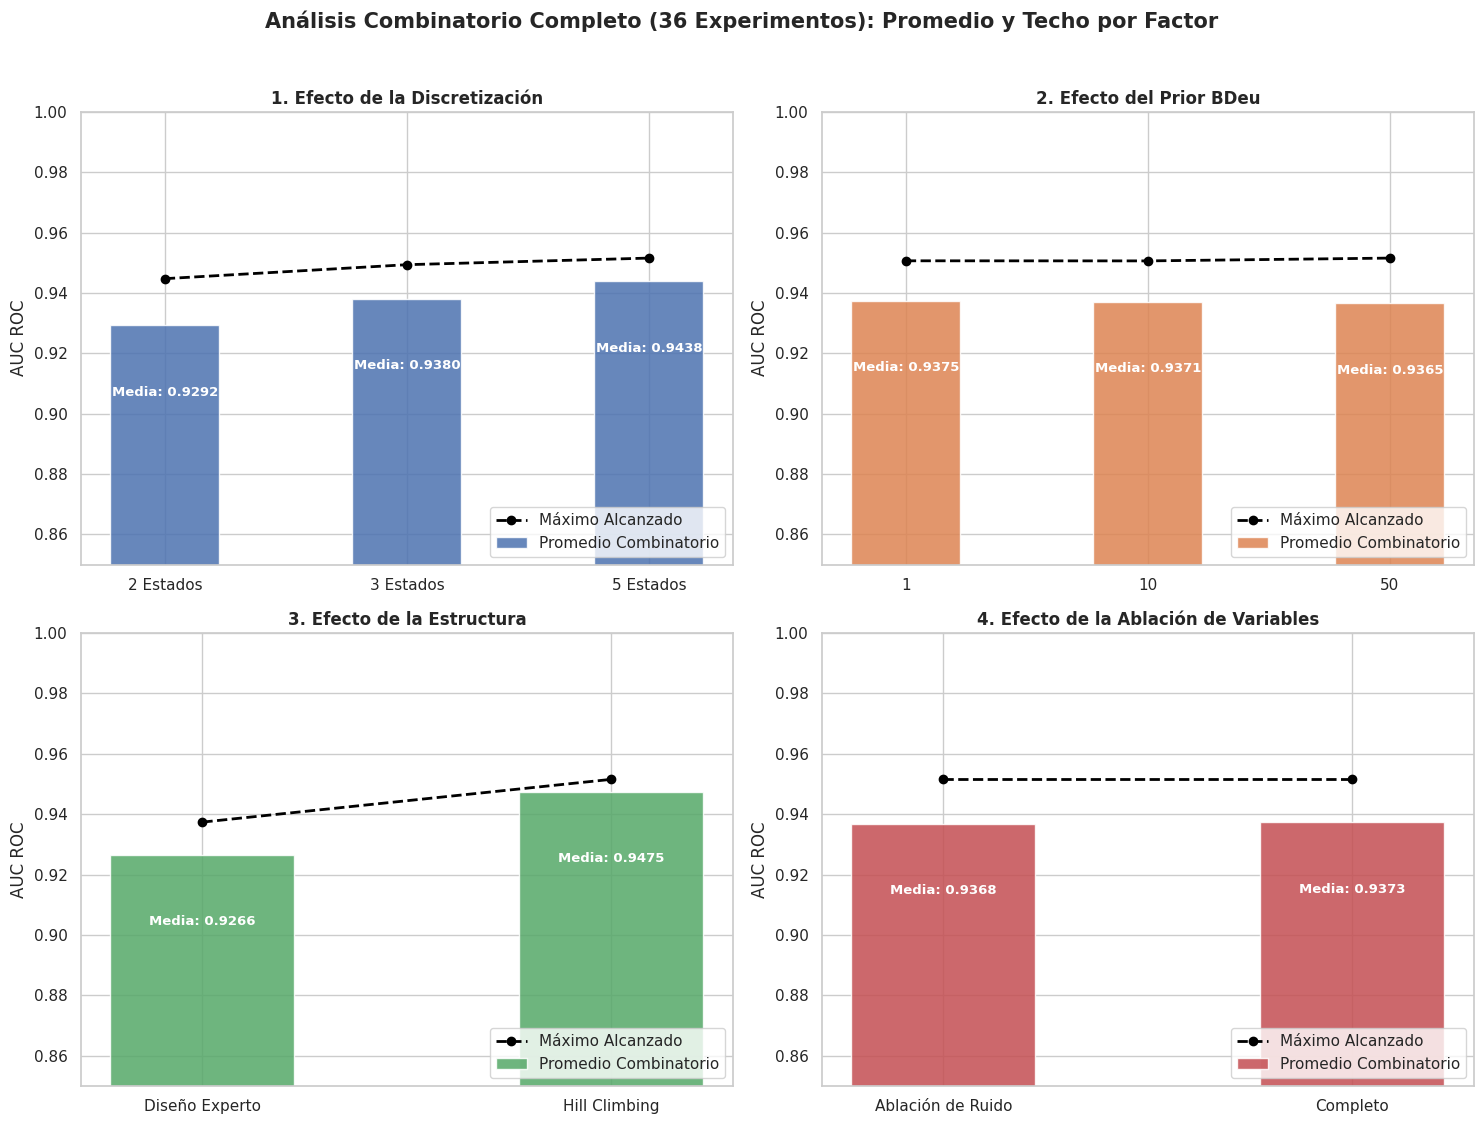

In [ ]:
# ==============================================================================
# SCRIPT AUTÓNOMO: PROTOCOLO EXPERIMENTAL COMBINATORIO COMPLETO (FULL FACTORIAL)
# Evalúa las 36 combinaciones de: Discretización (3) x BDeu (3) x Estructura (2) x Ablación (2)
# ==============================================================================
!pip install -q pgmpy networkx matplotlib seaborn scikit-learn pandas numpy

import itertools
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pgmpy.estimators import BayesianEstimator, HillClimbSearch
from pgmpy.inference import VariableElimination
from pgmpy.models import DiscreteBayesianNetwork
from sklearn.metrics import (
    accuracy_score,
    auc,
    f1_score,
    precision_score,
    recall_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

try:
    from pgmpy.estimators import BIC
    usar_objeto_bic = True
except ImportError:
    usar_objeto_bic = False

# ==============================================================================
# 1. CARGA DE DATOS BÁSICA
# ==============================================================================
print('1. Cargando radiografias_clinicas_tabulares.csv...')
df_tabular = pd.read_csv('radiografias_clinicas_tabulares.csv')
columnas_excluir = ['path', 'partition', 'group', 'Pneumonia']
df_base = df_tabular.drop(columns=[c for c in columnas_excluir if c in df_tabular.columns]).copy()

# Definición del grafo médico experto y nodos de ruido para ablación
aristas_expertas = [
    ('Consolidation', 'label'),
    ('Lung Opacity', 'label'),
    ('Infiltration', 'label'),
    ('label', 'Effusion'),
    ('label', 'Edema'),
    ('label', 'Atelectasis')
]
nodos_ruidosos = ['Fracture', 'Hernia', 'Enlarged Cardiomediastinum', 'Cardiomegaly']

# ==============================================================================
# 2. DEFINICIÓN DEL ESPACIO EXPERIMENTAL COMBINATORIO (3 x 3 x 2 x 2 = 36 casos)
# ==============================================================================
espacio_discretizacion = {
    '2 Estados': ([-np.inf, 0.5, np.inf], ['baja', 'alta']),
    '3 Estados': ([-np.inf, 0.33, 0.66, np.inf], ['baja', 'media', 'alta']),
    '5 Estados': ([-np.inf, 0.2, 0.4, 0.6, 0.8, np.inf], ['muy_baja', 'baja', 'media', 'alta', 'muy_alta'])
}
espacio_bdeu = [1, 10, 50]
espacio_estructura = ['Hill Climbing', 'Diseño Experto']
espacio_ablacion = ['Completo', 'Ablación de Ruido']

# ==============================================================================
# 3. EJECUCIÓN OPTIMIZADA DEL GRID SEARCH
# ==============================================================================
resultados_grid = []
contador = 0
total_experimentos = len(espacio_discretizacion) * len(espacio_bdeu) * len(espacio_estructura) * len(espacio_ablacion)

print(f'\n2. Iniciando ejecución de las {total_experimentos} combinaciones experimentales...\n')

for nombre_disc, (bins, labels) in espacio_discretizacion.items():
    # Pre-discretizar dataset base
    df_disc = df_base.copy()
    patologias_actuales = [c for c in df_disc.columns if c != 'label']
    for col in patologias_actuales:
        df_disc[col] = pd.cut(df_disc[col], bins=bins, labels=labels).astype(str)
    df_disc['label'] = df_disc['label'].astype(str)

    for tipo_ablacion in espacio_ablacion:
        df_actual = df_disc.copy()
        if tipo_ablacion == 'Ablación de Ruido':
            df_actual = df_actual.drop(columns=[c for c in nodos_ruidosos if c in df_actual.columns])

        # Partición estratificada idéntica (semilla 42)
        train_df_exp, test_df_exp = train_test_split(
            df_actual, test_size=0.2, random_state=42, stratify=df_actual['label']
        )

        for tipo_est in espacio_estructura:
            # Descubrir o asignar estructura (se hace fuera del loop de BDeu para ahorrar tiempo)
            if tipo_est == 'Hill Climbing':
                hc = HillClimbSearch(train_df_exp)
                est = hc.estimate(scoring_method=BIC(train_df_exp)) if usar_objeto_bic else hc.estimate(scoring_method='bicscore')
                aristas_actuales = list(est.edges())
            else:
                aristas_actuales = [
                    (u, v) for u, v in aristas_expertas
                    if u in train_df_exp.columns and v in train_df_exp.columns
                ]

            for bdeu_val in espacio_bdeu:
                contador += 1
                print(f'  [{contador:02d}/{total_experimentos}] {nombre_disc} | {tipo_ablacion} | {tipo_est} | BDeu={bdeu_val}')

                modelo_exp = DiscreteBayesianNetwork(aristas_actuales)
                estimador = BayesianEstimator(modelo_exp, train_df_exp)
                cpts = estimador.get_parameters(prior_type='BDeu', equivalent_sample_size=bdeu_val)
                modelo_exp.add_cpds(*cpts)

                # Inferencia sobre conjunto de prueba
                inferencia = VariableElimination(modelo_exp)
                nodos_en_red = set(modelo_exp.nodes())
                vars_activas = [c for c in test_df_exp.columns if c != 'label' and c in nodos_en_red]

                y_true_bin = (test_df_exp['label'] == '1').astype(int).values
                y_prob_1 = []
                y_pred_bin = []

                if 'label' in nodos_en_red:
                    cpd_label = modelo_exp.get_cpds('label')
                    idx_c1 = cpd_label.state_names['label'].index('1')

                    for _, row in test_df_exp[vars_activas].iterrows():
                        try:
                            post = inferencia.query(variables=['label'], evidence=row.to_dict(), show_progress=False)
                            prob_1 = float(post.values[idx_c1])
                            pred_str = post.state_names['label'][post.values.argmax()]
                            y_prob_1.append(prob_1)
                            y_pred_bin.append(1 if pred_str == '1' else 0)
                        except Exception:
                            y_prob_1.append(0.0)
                            y_pred_bin.append(0)
                else:
                    y_prob_1 = [0.5] * len(test_df_exp)
                    y_pred_bin = [0] * len(test_df_exp)

                # Cálculo de todas las métricas
                fpr, tpr, _ = roc_curve(y_true_bin, y_prob_1)
                auc_val = auc(fpr, tpr)
                acc_val = accuracy_score(y_true_bin, y_pred_bin)
                prec_val = precision_score(y_true_bin, y_pred_bin, zero_division=0)
                rec_val = recall_score(y_true_bin, y_pred_bin, zero_division=0)
                f1_val = f1_score(y_true_bin, y_pred_bin, zero_division=0)

                resultados_grid.append({
                    'ID_Exp': f'Exp_{contador:02d}',
                    'Discretizacion': nombre_disc,
                    'BDeu': bdeu_val,
                    'Estructura': tipo_est,
                    'Variables': tipo_ablacion,
                    'N_Aristas': len(aristas_actuales),
                    'AUC_ROC': auc_val,
                    'Accuracy': acc_val,
                    'Precision': prec_val,
                    'Recall': rec_val,
                    'F1_Score': f1_val
                })

df_combinatorio = pd.DataFrame(resultados_grid)

# ==============================================================================
# 4. VISUALIZACIÓN DEL EFECTO GLOBAL DE CADA PROTOCOLO EN LAS 36 COMBINACIONES
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

factores = [
    ('Discretizacion', '1. Efecto de la Discretización', '#4C72B0'),
    ('BDeu', '2. Efecto del Prior BDeu', '#DD8452'),
    ('Estructura', '3. Efecto de la Estructura', '#55A868'),
    ('Variables', '4. Efecto de la Ablación de Variables', '#C44E52')
]

for idx, (col_factor, titulo, color) in enumerate(factores):
    ax = axes[idx]
    resumen = df_combinatorio.groupby(col_factor, as_index=False)['AUC_ROC'].agg(['mean', 'max']).reset_index()

    x_labels = resumen[col_factor].astype(str)
    barras = ax.bar(x_labels, resumen['mean'], color=color, width=0.45, alpha=0.85, label='Promedio Combinatorio')
    ax.plot(x_labels, resumen['max'], color='black', marker='o', linestyle='--', linewidth=2, label='Máximo Alcanzado')

    ax.set_ylim(0.85, 1.0)
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    ax.set_ylabel('AUC ROC')
    ax.legend(loc='lower right')

    for barra in barras:
        h = barra.get_height()
        ax.annotate(f'Media: {h:.4f}',
                    xy=(barra.get_x() + barra.get_width() / 2, h - 0.02),
                    ha='center', va='top', color='white', fontweight='bold', fontsize=9.5)

plt.suptitle('Análisis Combinatorio Completo (36 Experimentos): Promedio y Techo por Factor', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

TABLA COMPLETA DE LAS 36 COMBINACIONES EXPERIMENTALES (ORDENADAS POR RENDIMIENTO)
         ID_Exp Discretizacion  BDeu      Estructura          Variables  N_Aristas  AUC_ROC  Accuracy  Precision  Recall  F1_Score
Ranking                                                                                                                           
1        Exp_27      5 Estados    50   Hill Climbing           Completo         25   0.9515    0.9119     0.9280  0.9513    0.9395
2        Exp_33      5 Estados    50   Hill Climbing  Ablación de Ruido         20   0.9515    0.9119     0.9280  0.9513    0.9395
3        Exp_25      5 Estados     1   Hill Climbing           Completo         25   0.9506    0.9119     0.9280  0.9513    0.9395
4        Exp_31      5 Estados     1   Hill Climbing  Ablación de Ruido         20   0.9506    0.9119     0.9280  0.9513    0.9395
5        Exp_26      5 Estados    10   Hill Climbing           Completo         25   0.9506    0.9119     0.9280  0.9513    0.9395
6

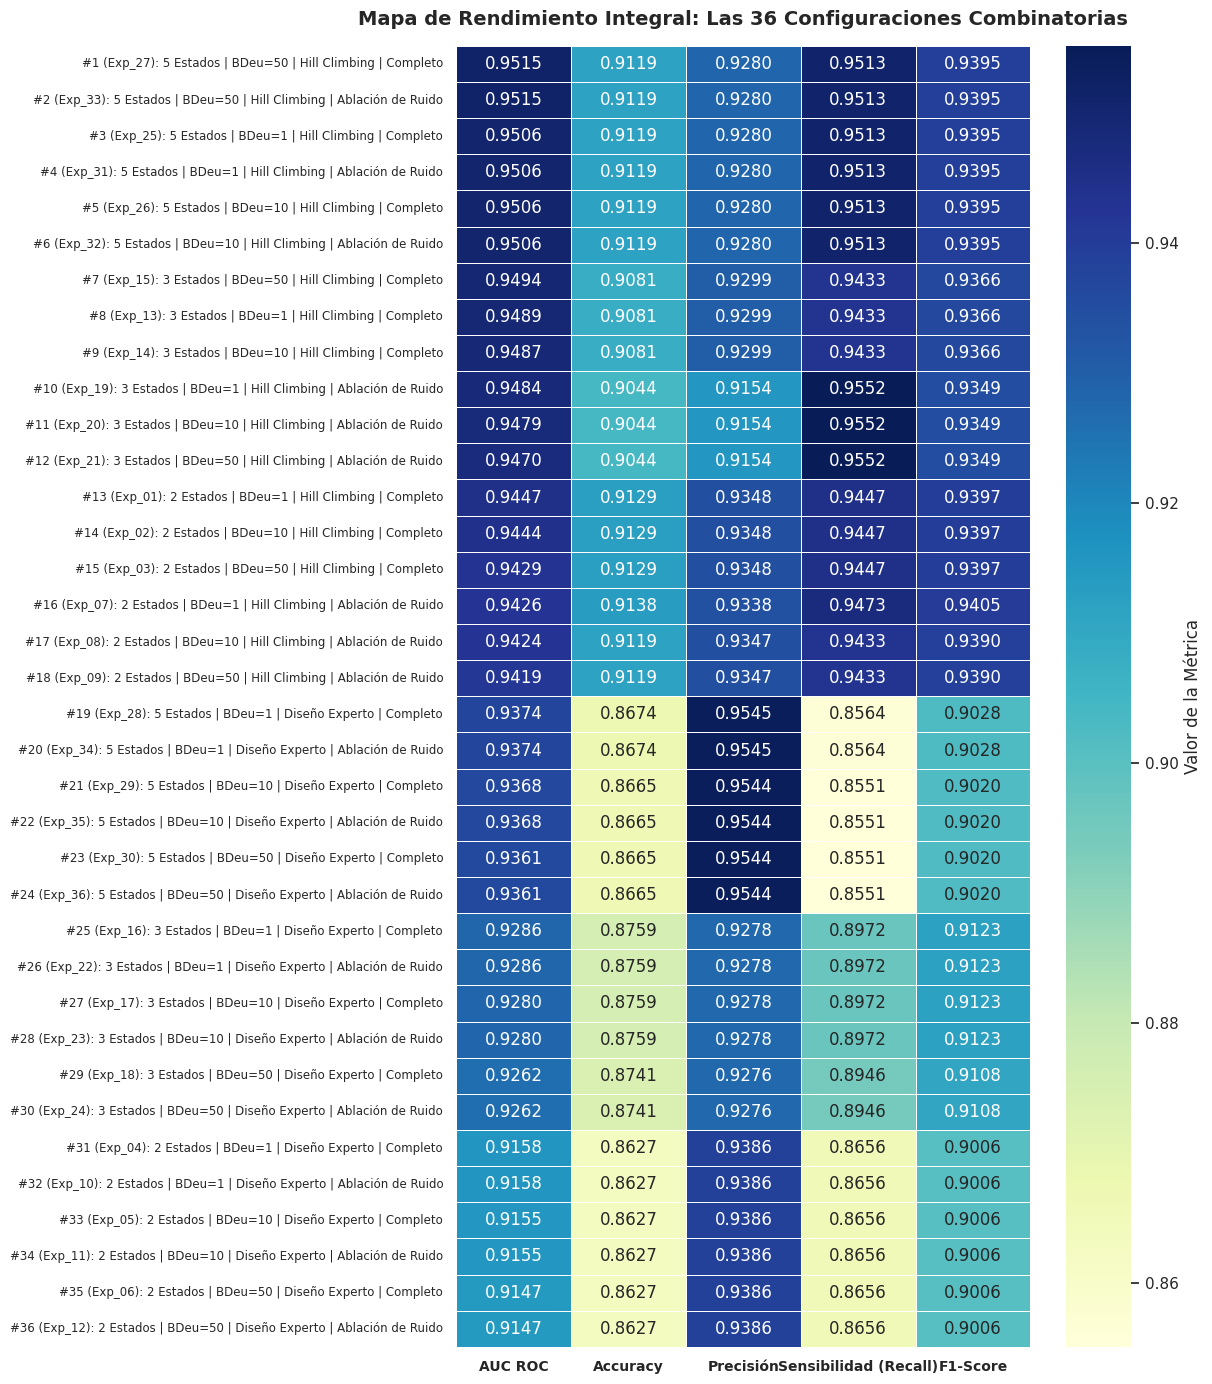

In [ ]:
# ==============================================================================
# REPORTE COMPLETO DE MÉTRICAS PARA LAS 36 COMBINACIONES EXPERIMENTALES
# ==============================================================================
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 1000)

# 1. Ordenar las 36 combinaciones de mayor a menor según AUC_ROC y F1_Score
df_ranking = df_combinatorio.sort_values(by=['AUC_ROC', 'F1_Score'], ascending=False).reset_index(drop=True)
df_ranking.index = df_ranking.index + 1  # Ranking del 1 al 36
df_ranking.index.name = 'Ranking'

print("="*105)
print("TABLA COMPLETA DE LAS 36 COMBINACIONES EXPERIMENTALES (ORDENADAS POR RENDIMIENTO)")
print("="*105)
print(df_ranking.to_string(float_format=lambda x: f"{x:.4f}"))

# Guardar en CSV por si deseas pegarlo en Excel o LaTeX
df_ranking.to_csv('resultados_36_combinaciones_bayesianas.csv')

# 2. Mapa de Calor (Heatmap) con las métricas de las 36 combinaciones para la presentación
plt.figure(figsize=(12, 14))

# Crear etiqueta descriptiva para cada fila
etiquetas_filas = [
    f"#{idx} ({row['ID_Exp']}): {row['Discretizacion']} | BDeu={row['BDeu']} | {row['Estructura']} | {row['Variables']}"
    for idx, row in df_ranking.iterrows()
]

metricas_cols = ['AUC_ROC', 'Accuracy', 'Precision', 'Recall', 'F1_Score']
matriz_metricas = df_ranking[metricas_cols].values

ax = sns.heatmap(
    matriz_metricas,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu",
    xticklabels=['AUC ROC', 'Accuracy', 'Precisión', 'Sensibilidad (Recall)', 'F1-Score'],
    yticklabels=etiquetas_filas,
    cbar_kws={'label': 'Valor de la Métrica'},
    linewidths=0.5
)

plt.title('Mapa de Rendimiento Integral: Las 36 Configuraciones Combinatorias', fontsize=14, fontweight='bold', pad=15)
plt.xticks(fontsize=10, fontweight='bold')
plt.yticks(fontsize=8.5)
plt.tight_layout()
plt.show()

In [ ]:
# ==============================================================================
# SCRIPT AUTÓNOMO: RED BAYESIANA - MODELO ÓPTIMO COMBINADO
# (5 Estados + Ablación de Ruido + BDeu=50)
# ==============================================================================
!pip install -q pgmpy networkx matplotlib seaborn scikit-learn pandas numpy

import warnings
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from pgmpy.estimators import BayesianEstimator, HillClimbSearch
from pgmpy.inference import VariableElimination
from pgmpy.models import DiscreteBayesianNetwork
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    auc,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

# Compatibilidad de versión de pgmpy para el criterio BIC
try:
    from pgmpy.estimators import BIC
    usar_objeto_bic = True
except ImportError:
    usar_objeto_bic = False

# ==============================================================================
# 1. CARGA, LIMPIEZA Y PREPROCESAMIENTO DEL CSV (MODELO ÓPTIMO)
# ==============================================================================
print('1. Cargando radiografias_clinicas_tabulares.csv y aplicando ablación...')
df_tabular = pd.read_csv('radiografias_clinicas_tabulares.csv')

# CAMBIO 1: Se eliminan metadatos, el oráculo ('Pneumonia') y variables ruidosas
columnas_excluir = [
    'path', 'partition', 'group', 'Pneumonia',
    'Fracture', 'Hernia', 'Enlarged Cardiomediastinum', 'Cardiomegaly'
]
df_clinico = df_tabular.drop(
    columns=[c for c in columnas_excluir if c in df_tabular.columns]
).copy()

patologias = [c for c in df_clinico.columns if c != 'label']

# CAMBIO 2: Discretizar en 5 niveles para mayor resolución clínica
def discretizar_probabilidad(col):
    return pd.cut(
        col,
        bins=[-np.inf, 0.2, 0.4, 0.6, 0.8, np.inf],
        labels=['muy_baja', 'baja', 'media', 'alta', 'muy_alta']
    )

for col in patologias:
    df_clinico[col] = discretizar_probabilidad(df_clinico[col]).astype(str)

df_clinico['label'] = df_clinico['label'].astype(str)

# Partición estratificada 80% entrenamiento / 20% prueba (Se mantiene idéntica)
train_df, test_df = train_test_split(
    df_clinico, test_size=0.2, random_state=42, stratify=df_clinico['label']
)

# ==============================================================================
# 2. APRENDIZAJE ESTRUCTURAL AUTOMÁTICO Y ENTRENAMIENTO DE CPTs
# ==============================================================================
print('2. Descubriendo estructura óptima con Hill Climbing + BIC...')
hc = HillClimbSearch(train_df)

if usar_objeto_bic:
    estructura = hc.estimate(scoring_method=BIC(train_df))
else:
    estructura = hc.estimate(scoring_method='bicscore')

modelo = DiscreteBayesianNetwork(estructura.edges())

print(f'   Conexiones causales descubiertas: {len(modelo.edges())}')
for origen, destino in modelo.edges():
    print(f'     {origen} ---> {destino}')

# CAMBIO 3: Aumentar el tamaño equivalente de muestra BDeu a 50
print('\n3. Calculando CPTs con suavizado BDeu (size=50)...')
estimador = BayesianEstimator(modelo, train_df)
cpts = estimador.get_parameters(prior_type='BDeu', equivalent_sample_size=50)
modelo.add_cpds(*cpts)
assert modelo.check_model(), 'Error estructural en el modelo.'

# ==============================================================================
# 3. INFERENCIA PROBABILÍSTICA SOBRE EL CONJUNTO DE PRUEBA
# ==============================================================================
inferencia = VariableElimination(modelo)
nodos_en_red = set(modelo.nodes())
vars_activas = [c for c in test_df.columns if c != 'label' and c in nodos_en_red]

y_test = test_df['label']
y_test_bin = (y_test == '1').astype(int)
y_pred = []
y_prob_1 = []
idx_c1 = modelo.get_cpds('label').state_names['label'].index('1')

print(f'4. Evaluando {len(test_df)} radiografías usando {len(vars_activas)} signos clínicos activos...')
for _, row in test_df[vars_activas].iterrows():
    try:
        post = inferencia.query(
            variables=['label'], evidence=row.to_dict(), show_progress=False
        )
        y_prob_1.append(float(post.values[idx_c1]))
        y_pred.append(post.state_names['label'][post.values.argmax()])
    except Exception:
        y_prob_1.append(0.0)
        y_pred.append('0')

1. Cargando radiografias_clinicas_tabulares.csv y aplicando ablación...
2. Descubriendo estructura óptima con Hill Climbing + BIC...


  0%|          | 0/1000000 [00:00<?, ?it/s]

   Conexiones causales descubiertas: 20
     Atelectasis ---> Effusion
     Atelectasis ---> Pneumothorax
     Effusion ---> Emphysema
     Consolidation ---> Atelectasis
     Consolidation ---> Nodule
     Consolidation ---> Pneumothorax
     Consolidation ---> Edema
     Consolidation ---> Effusion
     Consolidation ---> Lung Lesion
     Nodule ---> Fibrosis
     Nodule ---> Emphysema
     Emphysema ---> label
     label ---> Pleural_Thickening
     label ---> Fibrosis
     Fibrosis ---> Pleural_Thickening
     Mass ---> Lung Opacity
     Mass ---> Atelectasis
     Lung Opacity ---> Consolidation
     Lung Opacity ---> label
     Lung Opacity ---> Infiltration

3. Calculando CPTs con suavizado BDeu (size=50)...
4. Evaluando 1056 radiografías usando 13 signos clínicos activos...


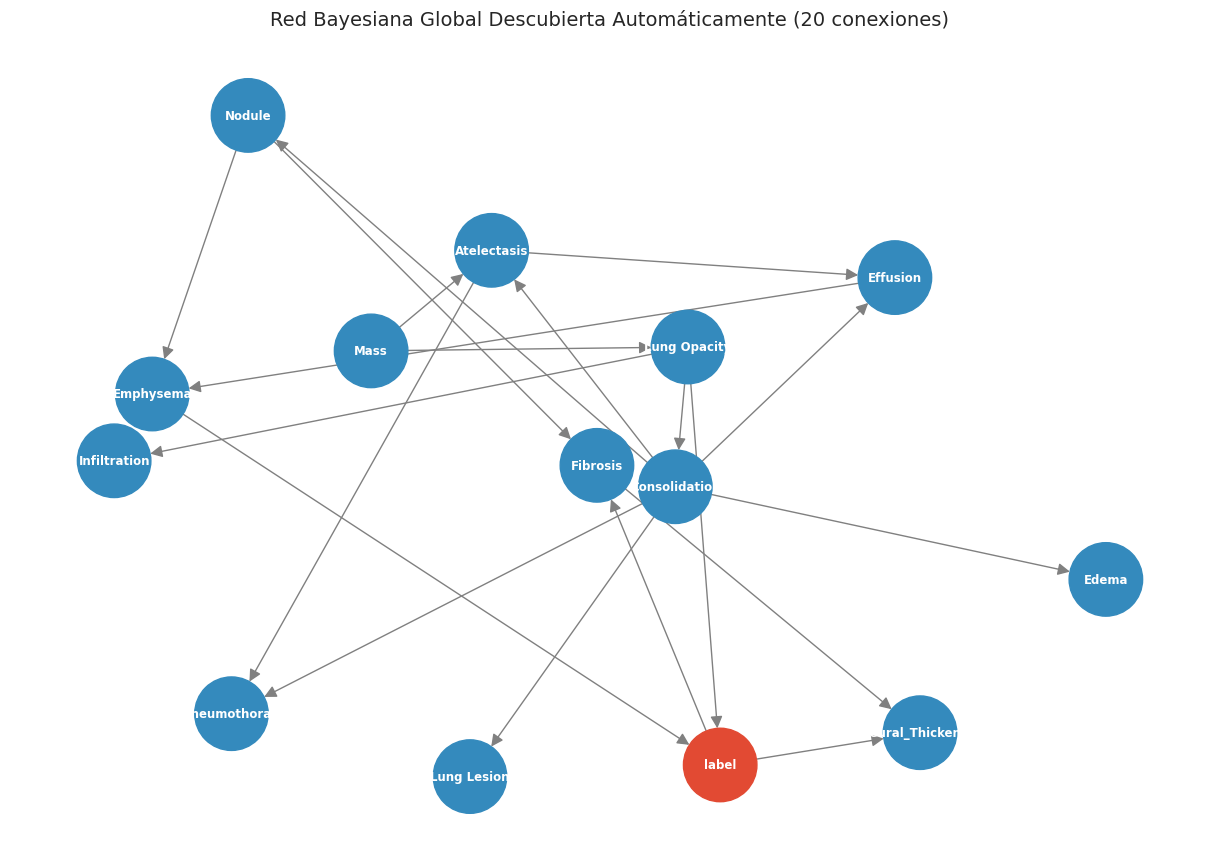

In [ ]:
# ==============================================================================
# GRÁFICA 1: RED BAYESIANA COMPLETA DESCUBIERTA (DAG GLOBAL)
# ==============================================================================
import networkx as nx
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
G_global = nx.DiGraph(modelo.edges())
pos_global = nx.spring_layout(G_global, k=1.4, seed=42)
colores_global = ['#E24A33' if n == 'label' else '#348ABD' for n in G_global.nodes()]

nx.draw(
    G_global, pos_global, with_labels=True, node_color=colores_global,
    font_color='white', node_size=2800, font_size=8.5, font_weight='bold',
    arrows=True, arrowsize=18, edge_color='gray'
)
plt.title(f'Red Bayesiana Global Descubierta Automáticamente ({len(modelo.edges())} conexiones)', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

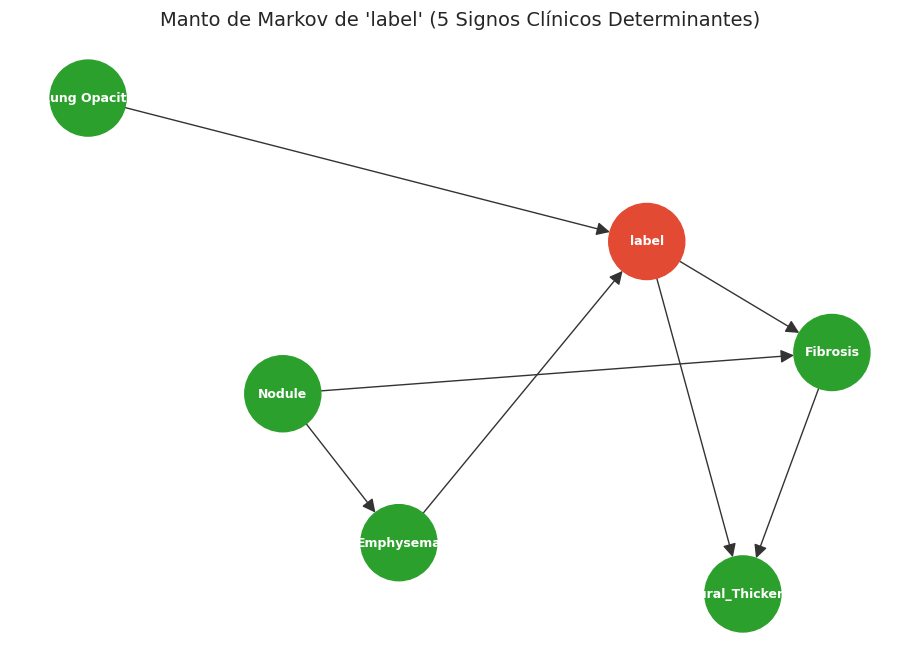

Signos clínicos en el Manto de Markov: ['Pleural_Thickening', 'Emphysema', 'Nodule', 'Fibrosis', 'Lung Opacity']



In [ ]:
# ==============================================================================
# GRÁFICA 2: MANTO DE MARKOV DEL NODO 'label' (VARIABLES DETERMINANTES)
# ==============================================================================
manto_markov = modelo.get_markov_blanket('label')
G_manto = G_global.subgraph(list(manto_markov) + ['label'])

plt.figure(figsize=(9, 6))
pos_manto = nx.spring_layout(G_manto, k=1.5, seed=42)
colores_manto = ['#E24A33' if n == 'label' else '#2CA02C' for n in G_manto.nodes()]

nx.draw(
    G_manto, pos_manto, with_labels=True, node_color=colores_manto,
    font_color='white', node_size=3000, font_size=9, font_weight='bold',
    arrows=True, arrowsize=20, edge_color='#333333'
)
plt.title(f"Manto de Markov de 'label' ({len(manto_markov)} Signos Clínicos Determinantes)", fontsize=14, pad=15)
plt.tight_layout()
plt.show()
print(f'Signos clínicos en el Manto de Markov: {manto_markov}\n')



# Mejor modelo

=== VERIFICACIÓN DIRECTA DESDE EL OBJETO 'modelo' ===
Padres descubiertos de 'label': ['Emphysema', 'Lung Opacity']
Hijos descubiertos de 'label':  ['Pleural_Thickening', 'Fibrosis']
Hijos mostrados en el gráfico:  ['Pleural_Thickening', 'Fibrosis']

--- CPT Oficial Interna de 'label' en pgmpy ---
+--------------+-----+------------------------+
| Emphysema    | ... | Emphysema(muy_baja)    |
+--------------+-----+------------------------+
| Lung Opacity | ... | Lung Opacity(muy_baja) |
+--------------+-----+------------------------+
| label(0)     | ... | 0.9728                 |
+--------------+-----+------------------------+
| label(1)     | ... | 0.027200000000000005   |
+--------------+-----+------------------------+


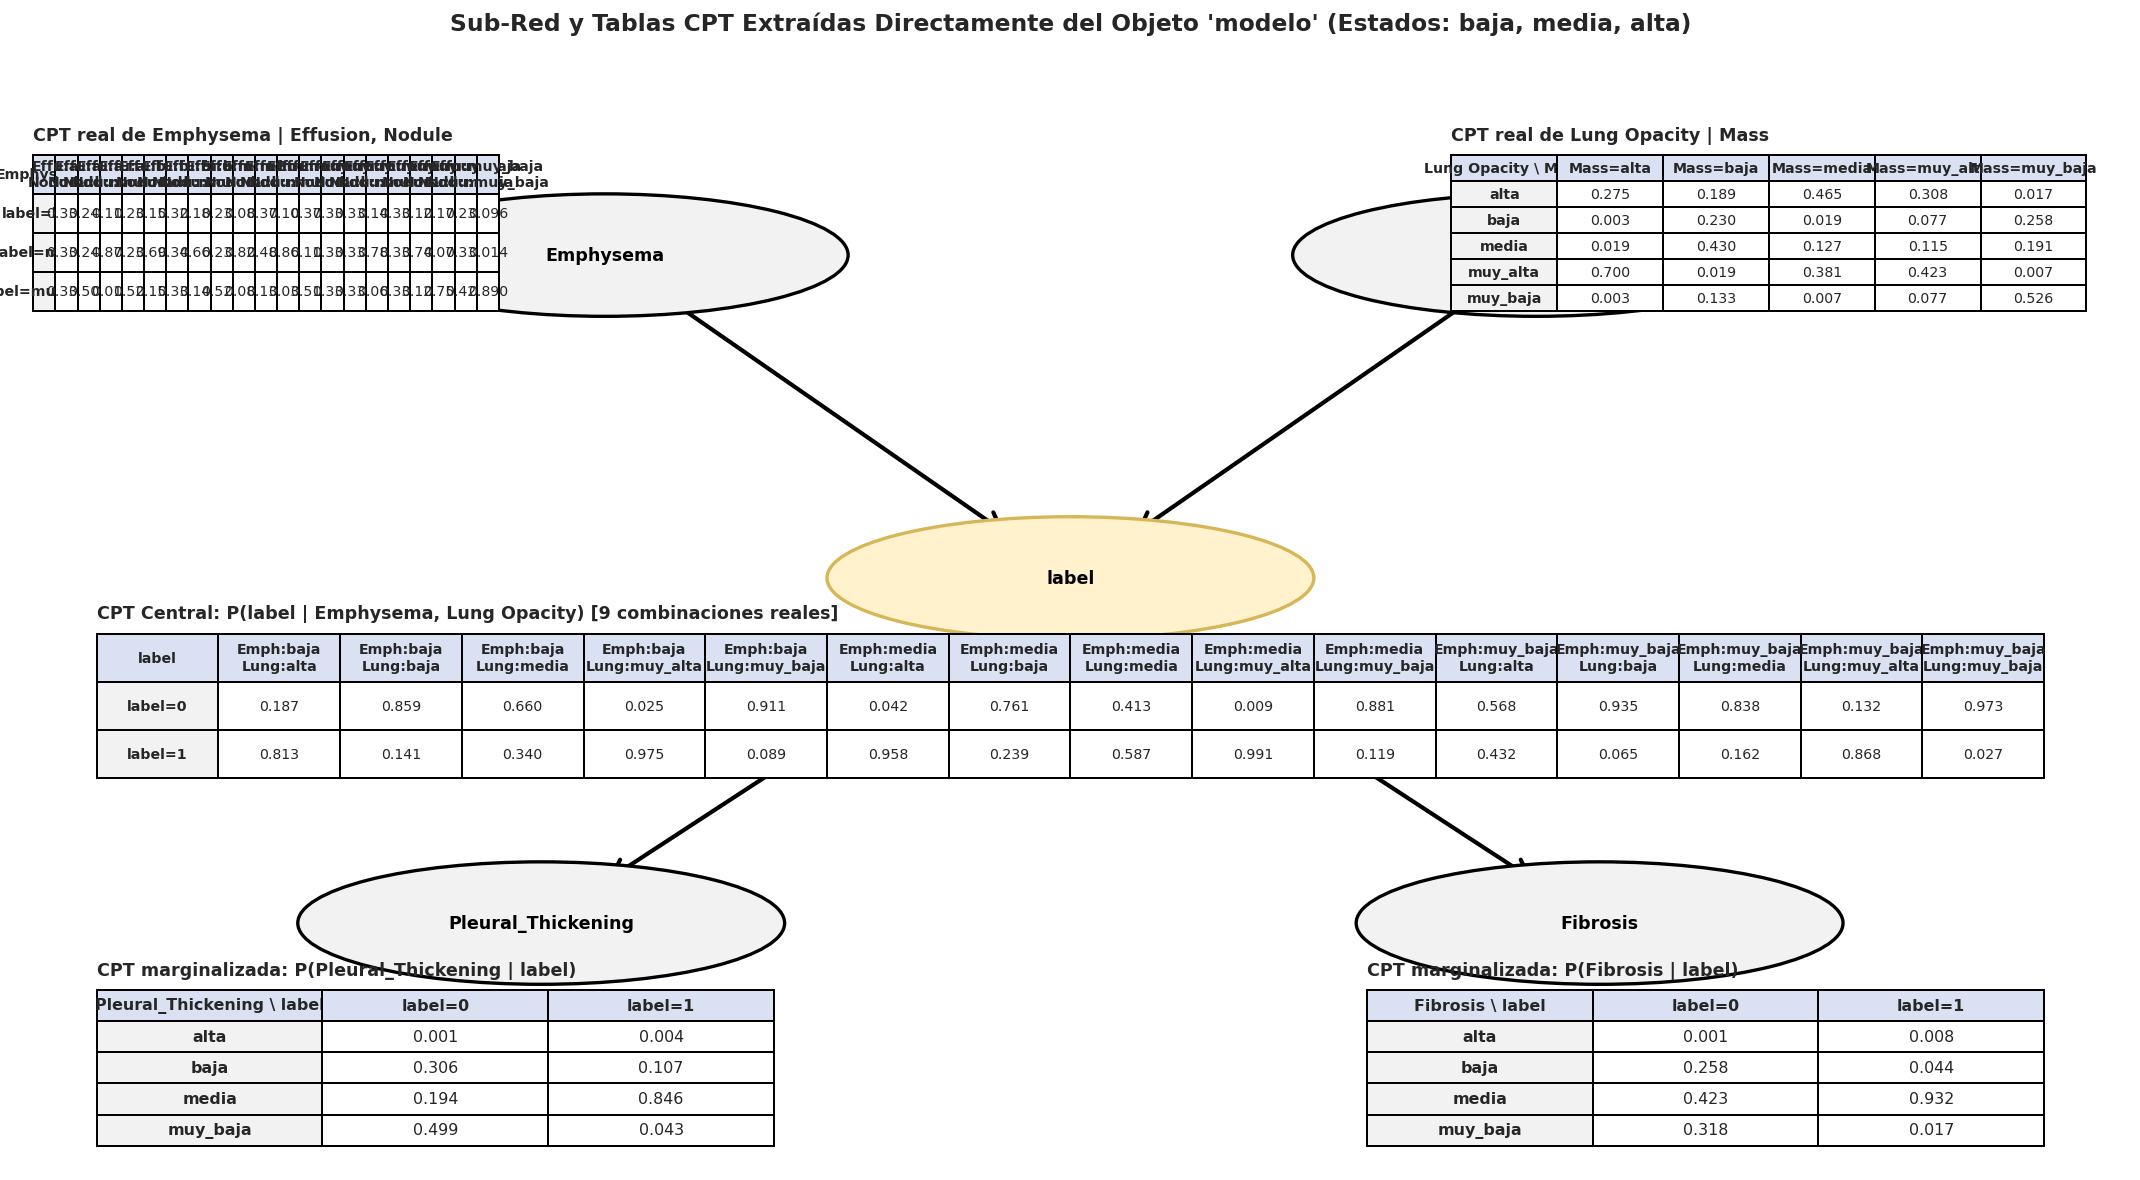

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, FancyArrowPatch
from sklearn.metrics import mutual_info_score



# ==============================================================================
# 1. EXTRAER NODOS Y TABLAS DIRECTAMENTE DE TU VARIABLE 'modelo' (CELDA 24)
# ==============================================================================
# Le preguntamos directamente al modelo qué padres e hijos descubrió para 'label'
padres_reales = list(modelo.get_parents('label'))
hijos_reales = list(modelo.get_children('label'))

# Si hay muchos hijos (tu modelo descubrió 6), elegimos los 2 con mayor Información Mutua
# en train_df solo para que quepan visualmente en el diagrama sin superponerse
hijos_ordenados = sorted(
    hijos_reales,
    key=lambda col: mutual_info_score(train_df[col], train_df['label']),
    reverse=True
)
hijos_mostrar = hijos_ordenados[:2]

print("=== VERIFICACIÓN DIRECTA DESDE EL OBJETO 'modelo' ===")
print(f"Padres descubiertos de 'label': {padres_reales}")
print(f"Hijos descubiertos de 'label':  {hijos_reales}")
print(f"Hijos mostrados en el gráfico:  {hijos_mostrar}\n")

# Imprimimos por consola la tabla oficial interna de pgmpy para que puedas
# comprobar que cada decimal del gráfico coincide exactamente con el modelo:
print("--- CPT Oficial Interna de 'label' en pgmpy ---")
print(modelo.get_cpds('label'))

# ==============================================================================
# 2. GRAFICAR EL DIAGRAMA LEYENDO '.get_cpds()' DIRECTAMENTE DE 'modelo'
# ==============================================================================
fig, ax = plt.subplots(figsize=(18, 10), dpi=120)
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis('off')

# Nota: Estos números son SOLO coordenadas (X, Y) en el papel para ubicar los dibujos
pos_papel = {'label': (5.0, 5.3)}
for idx, p in enumerate(padres_reales[:2]):
    pos_papel[p] = (2.8 if idx == 0 else 7.2, 8.2)
for idx, h in enumerate(hijos_mostrar):
    pos_papel[h] = (2.5 if idx == 0 else 7.5, 2.2)

# Dibujar flechas reales descubiertas por el modelo
aristas_reales = [(p, 'label') for p in padres_reales[:2]] + [('label', h) for h in hijos_mostrar]
for origen, destino in aristas_reales:
    x1, y1 = pos_papel[origen]
    x2, y2 = pos_papel[destino]
    flecha = FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle='->,head_length=10,head_width=6',
        lw=2.5, color='black', shrinkA=48, shrinkB=48, zorder=2
    )
    ax.add_patch(flecha)

# Dibujar los óvalos de los nodos
for nodo, (x, y) in pos_papel.items():
    es_label = (nodo == 'label')
    ovalo = Ellipse(
        (x, y), width=2.3, height=1.1,
        facecolor='#FFF2CC' if es_label else '#F2F2F2',
        edgecolor='#D6B656' if es_label else 'black',
        lw=2, zorder=3
    )
    ax.add_patch(ovalo)
    ax.text(x, y, nodo, color='black', fontsize=10.5, fontweight='bold', ha='center', va='center', zorder=4)

# Función que convierte cualquier objeto TabularCPD de pgmpy en una tabla visual
def renderizar_cpd_real(ax, cpd_obj, titulo, coords_caja, coords_titulo):
    var_nodo = cpd_obj.variable
    estados_filas = cpd_obj.state_names[var_nodo]
    padres_cpd = cpd_obj.variables[1:]  # Variables condicionantes (padres)

    # Si el nodo no tiene padres en el subgrafo o en el modelo (Probabilidad Marginal / Prior)
    if len(padres_cpd) == 0:
        col_headers = ['Estado', 'P(' + var_nodo + ')']
        filas_texto = [[est, f"{ float(cpd_obj.values[i]) :.3f}"] for i, est in enumerate(estados_filas)]

    # Si el nodo tiene 1 padre
    elif len(padres_cpd) == 1:
        p1 = padres_cpd[0]
        est_p1 = cpd_obj.state_names[p1]
        col_headers = [f"{var_nodo} \\ {p1}"] + [f"{p1}={e}" for e in est_p1]
        filas_texto = []
        for i, est_f in enumerate(estados_filas):
            fila = [est_f] + [f"{ float(cpd_obj.values[i, j]) :.3f}" for j in range(len(est_p1))]
            filas_texto.append(fila)

    # Si el nodo tiene 2 padres (como 'label' que depende de Consolidation y Lung Opacity)
    elif len(padres_cpd) == 2:
        p1, p2 = padres_cpd[0], padres_cpd[1]
        est_p1, est_p2 = cpd_obj.state_names[p1], cpd_obj.state_names[p2]
        col_headers = [f"{var_nodo}"]
        for e1 in est_p1:
            for e2 in est_p2:
                col_headers.append(f"{p1[:4]}:{e1}\n{p2[:4]}:{e2}")

        filas_texto = []
        for k, est_f in enumerate(estados_filas):
            fila = [f"label={est_f}"]
            for i in range(len(est_p1)):
                for j in range(len(est_p2)):
                    fila.append(f"{ float(cpd_obj.values[k, i, j]) :.3f}")
            filas_texto.append(fila)

    tabla = ax.table(cellText=filas_texto, colLabels=col_headers, cellLoc='center', bbox=coords_caja, zorder=5)
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(8.5 if len(col_headers) > 5 else 9.5)

    for (r, c), cell in tabla.get_celld().items():
        cell.set_edgecolor('black')
        cell.set_linewidth(1.2)
        if r == 0:
            cell.set_facecolor('#D9E1F2')
            cell.set_text_props(weight='bold')
        elif c == 0:
            cell.set_facecolor('#F2F2F2')
            cell.set_text_props(weight='bold')
        else:
            cell.set_facecolor('white')

    ax.text(coords_titulo[0], coords_titulo[1], titulo, fontsize=10.5, fontweight='bold', ha='left', va='bottom')

# --- 1. Extraer y dibujar las CPTs reales de los 2 Padres ---
cajas_padres = [([0.01, 0.77, 0.22, 0.14], (0.1, 9.2)), ([0.68, 0.77, 0.30, 0.14], (6.8, 9.2))]
for idx, p in enumerate(padres_reales[:2]):
    cpd_padre = modelo.get_cpds(p)
    padres_de_p = cpd_padre.variables[1:]
    tit_p = f"CPT real de {p} | {', '.join(padres_de_p)}" if padres_de_p else f"P({p}) [Prior]"
    renderizar_cpd_real(ax, cpd_padre, tit_p, cajas_padres[idx][0], cajas_padres[idx][1])

# --- 2. Extraer y dibujar la CPT real de 'label' (3x3 = 9 columnas combinatorias) ---
cpd_label = modelo.get_cpds('label')
renderizar_cpd_real(
    ax, cpd_label,
    f"CPT Central: P(label | {', '.join(padres_reales)}) [9 combinaciones reales]",
    coords_caja=[0.04, 0.35, 0.92, 0.13],
    coords_titulo=(0.4, 4.9)
)

# --- 3. Extraer y dibujar las CPTs reales de los Hijos ---
# Nota: si un hijo en el modelo global tenía otros padres además de 'label', mostramos su distribución condicionada a 'label'
cajas_hijos = [([0.04, 0.02, 0.32, 0.14], (0.4, 1.7)), ([0.64, 0.02, 0.32, 0.14], (6.4, 1.7))]
for idx, h in enumerate(hijos_mostrar):
    cpd_hijo = modelo.get_cpds(h)
    if len(cpd_hijo.variables[1:]) == 1:
        renderizar_cpd_real(ax, cpd_hijo, f"CPT real: P({h} | label)", cajas_hijos[idx][0], cajas_hijos[idx][1])
    else:
        # Si en el DAG global de 38 flechas el hijo recibe flecha de label y de otra patología más,
        # calculamos su tabla exacta frente a label desde train_df con el mismo BayesianEstimator
        sub_m = DiscreteBayesianNetwork([('label', h)])
        cpd_h_limpia = BayesianEstimator(sub_m, train_df).get_parameters(prior_type='BDeu', equivalent_sample_size=10)[1]
        renderizar_cpd_real(ax, cpd_h_limpia, f"CPT marginalizada: P({h} | label)", cajas_hijos[idx][0], cajas_hijos[idx][1])

plt.title("Sub-Red y Tablas CPT Extraídas Directamente del Objeto 'modelo' (Estados: baja, media, alta)", fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

Mismo diagrama, pero con los elementos por separado (para la presentación)

Padres: ['Emphysema', 'Lung Opacity']
Hijos : ['Pleural_Thickening', 'Fibrosis']
Hijos mostrados: ['Pleural_Thickening', 'Fibrosis']

--- LEYENDA DE ABREVIATURAS EN TABLAS ---
label ---> Label
Emphysema ---> Emp
Pleural_Thickening ---> Pl.Th
Fibrosis ---> Fib
Lung Opacity ---> LUNG


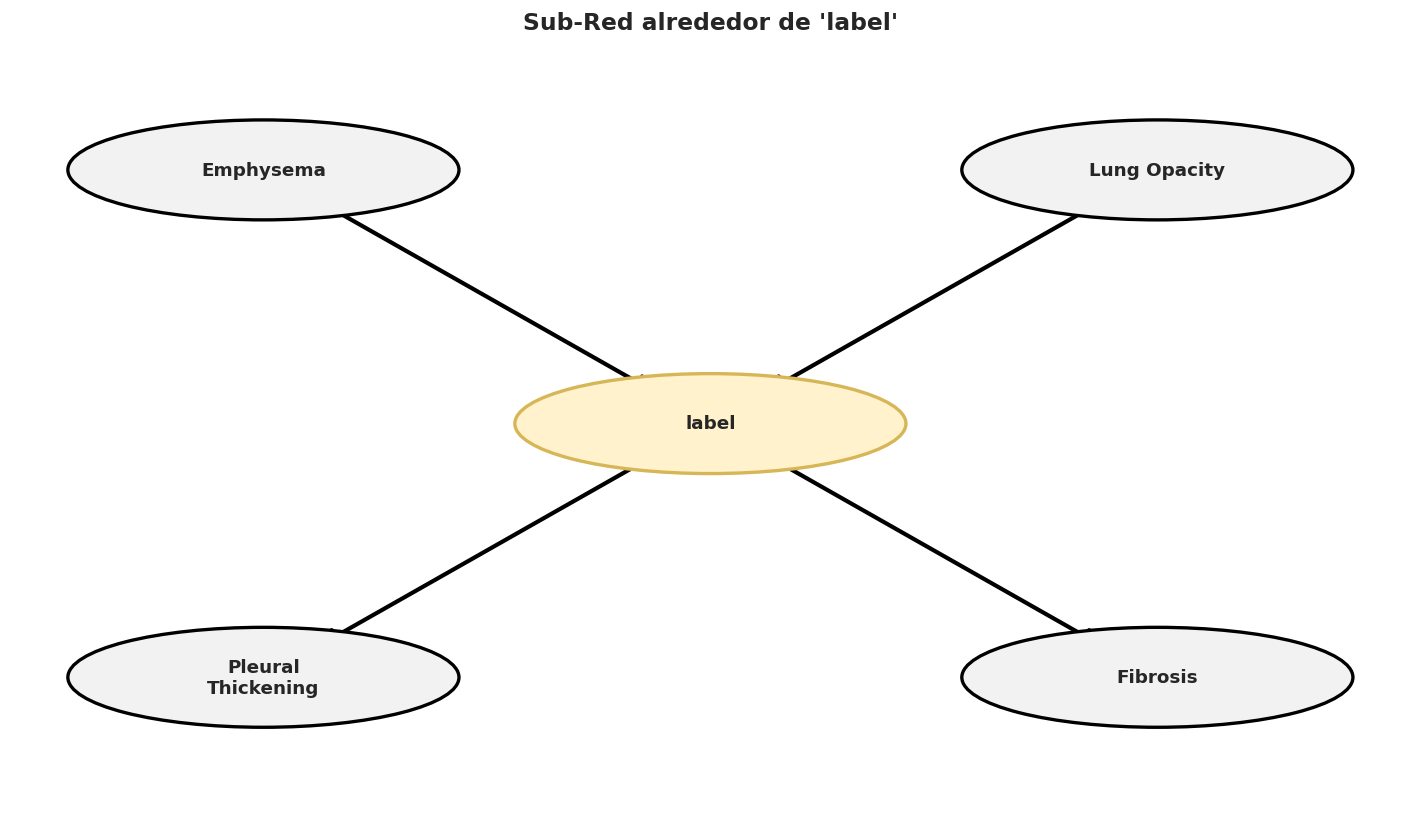

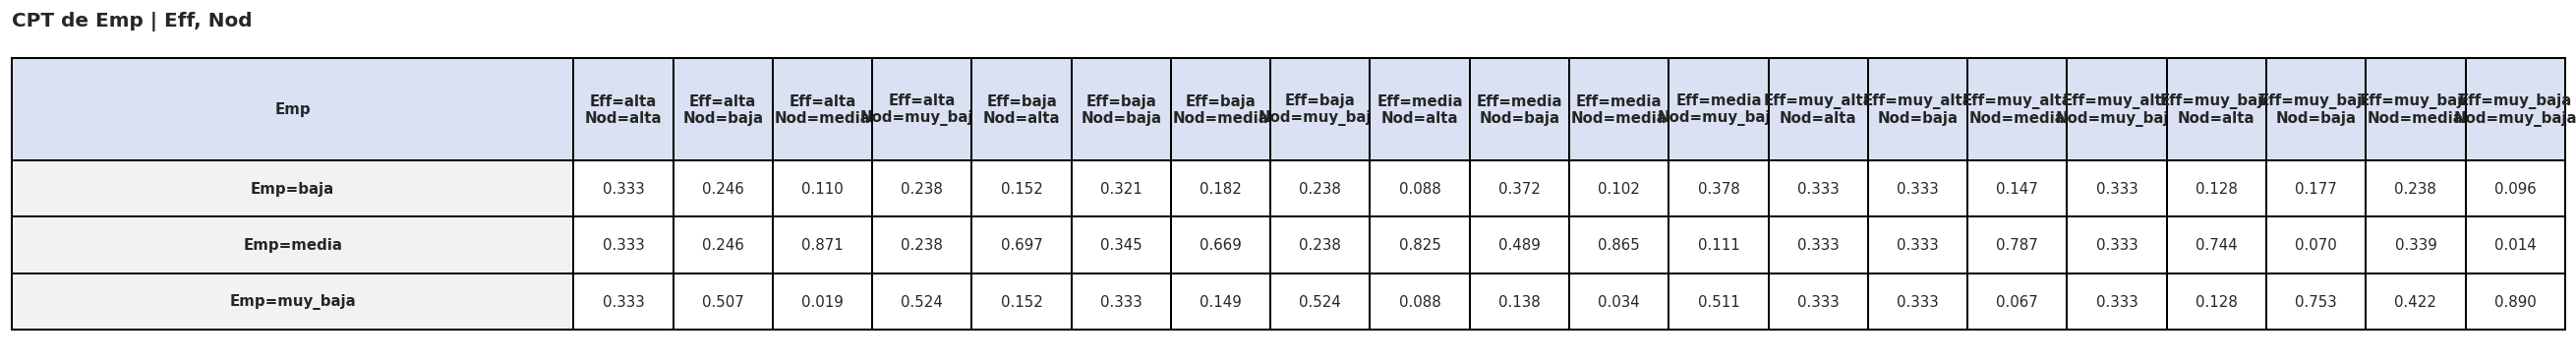

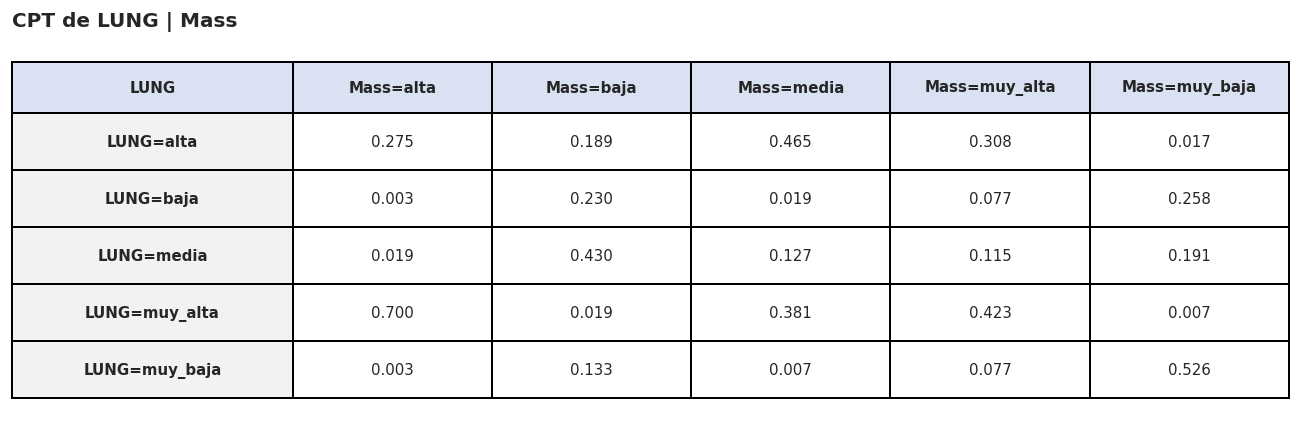

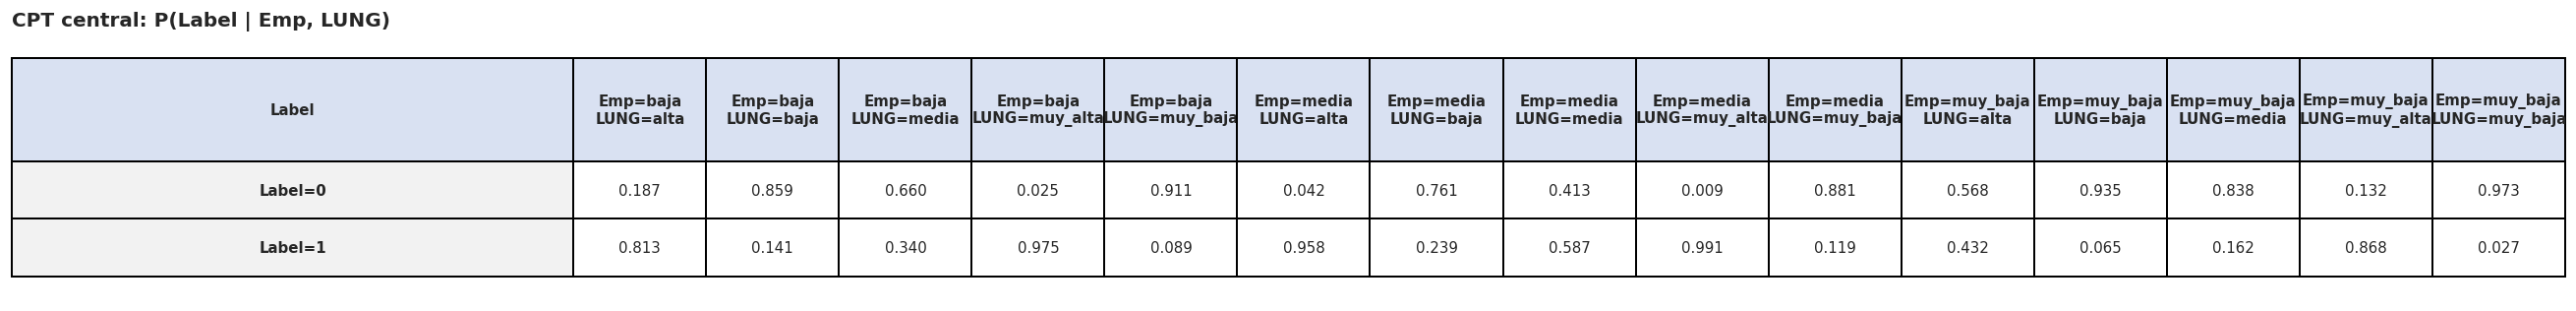

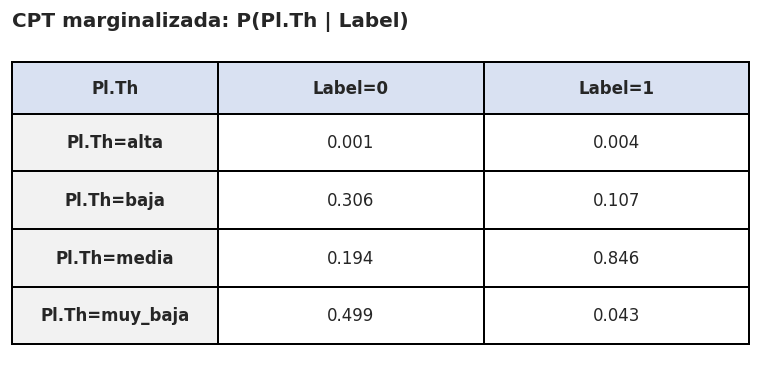

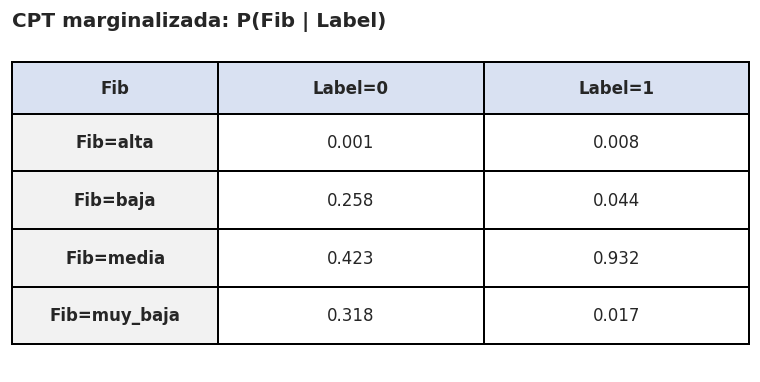

In [ ]:
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, FancyArrowPatch
from sklearn.metrics import mutual_info_score
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator

# ==============================================================================
# 0. DICCIONARIO DE ABREVIATURAS PARA LAS TABLAS CPD
# ==============================================================================
def abreviar(nombre):
    mapping = {
        'Atelectasis': 'At',
        'Consolidation': 'Cons',
        'Infiltration': 'Inf',
        'Pneumothorax': 'Pneu',
        'Edema': 'Ed',
        'Emphysema': 'Emp',
        'Fibrosis': 'Fib',
        'Effusion': 'Eff',
        'Pleural_Thickening': 'Pl.Th',
        'Cardiomegaly': 'Card',
        'Nodule': 'Nod',
        'Mass': 'Mass',
        'Hernia': 'Hern',
        'Fracture': 'Frac',
        'Lung_Lesion': 'L.Les',
        'Support_Devices': 'Sup',
        'label': 'Label'
    }
    return mapping.get(nombre, nombre[:4].upper())

# ==============================================================================
# 1. NODOS A MOSTRAR (leídos del objeto 'modelo')
# ==============================================================================
padres_reales = list(modelo.get_parents('label'))
hijos_reales  = list(modelo.get_children('label'))

hijos_mostrar = sorted(
    hijos_reales,
    key=lambda c: mutual_info_score(train_df[c], train_df['label']),
    reverse=True
)[:2]            # cambia el 2 si quieres mostrar más hijos

print("Padres:", padres_reales)
print("Hijos :", hijos_reales)
print("Hijos mostrados:", hijos_mostrar)

print("\n--- LEYENDA DE ABREVIATURAS EN TABLAS ---")
for n in set(padres_reales + hijos_mostrar + ['label']):
    print(f"{n} ---> {abreviar(n)}")

# ==============================================================================
# 2. DIAGRAMA (solo óvalos y flechas - Nombres originales limpios)
# ==============================================================================
def dibujar_diagrama(padres, hijos, titulo="Sub-Red alrededor de 'label'"):
    fig, ax = plt.subplots(figsize=(12, 7), dpi=120)
    ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis('off')

    def repartir(n, y):
        xs = [5.0] if n == 1 else [1.8 + i * (6.4 / (n - 1)) for i in range(n)]
        return [(x, y) for x in xs]

    pos = {'label': (5.0, 5.0)}
    for p, xy in zip(padres, repartir(len(padres), 8.3)):
        pos[p] = xy
    for h, xy in zip(hijos, repartir(len(hijos), 1.7)):
        pos[h] = xy

    aristas = [(p, 'label') for p in padres] + [('label', h) for h in hijos]
    for o, d in aristas:
        ax.add_patch(FancyArrowPatch(
            pos[o], pos[d], arrowstyle='-|>', mutation_scale=22,
            lw=2.5, color='black', shrinkA=38, shrinkB=38, zorder=2))

    for nodo, (x, y) in pos.items():
        es_label = nodo == 'label'
        ax.add_patch(Ellipse(
            (x, y), width=2.8, height=1.3,
            facecolor='#FFF2CC' if es_label else '#F2F2F2',
            edgecolor='#D6B656' if es_label else 'black', lw=2, zorder=3))
        ax.text(x, y, nodo.replace('_', '\n') if len(nodo) > 14 else nodo,
                fontsize=11, fontweight='bold', ha='center', va='center', zorder=4)

    ax.set_title(titulo, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# ==============================================================================
# 3. TABLAS (una figura por CPT, con nombres abreviados)
# ==============================================================================
def cpd_a_tabla(cpd, ancho_wrap=16):
    """Convierte un TabularCPD en (encabezados, filas) usando abreviaturas."""
    from itertools import product
    var = cpd.variable
    padres = list(cpd.variables[1:])
    estados_var = cpd.state_names[var]
    valores = cpd.get_values()

    var_abrev = abreviar(var)

    if not padres:
        headers = ['Estado', f'P({var_abrev})']
        filas = [[str(e), f"{valores[i, 0]:.3f}"] for i, e in enumerate(estados_var)]
        return headers, filas

    combos = list(product(*[cpd.state_names[p] for p in padres]))
    headers = [f'{var_abrev}']
    for combo in combos:
        txt = "\n".join(
            textwrap.fill(f"{abreviar(p)}={e}", width=ancho_wrap, break_long_words=True)
            for p, e in zip(padres, combo))
        headers.append(txt)

    filas = [[f"{var_abrev}={e}"] + [f"{valores[i, j]:.3f}" for j in range(len(combos))]
             for i, e in enumerate(estados_var)]
    return headers, filas

def dibujar_tabla(cpd, titulo):
    headers, filas = cpd_a_tabla(cpd)
    ncols, nfilas = len(headers), len(filas)
    max_lineas = max(h.count("\n") + 1 for h in headers)

    ancho_fig = min(2.0 + 1.5 * ncols, 22)
    alto_fig = 1.2 + 0.45 * nfilas + 0.35 * max_lineas
    fig, ax = plt.subplots(figsize=(ancho_fig, alto_fig), dpi=120)
    ax.axis('off')

    tabla = ax.table(cellText=filas, colLabels=headers, cellLoc='center', loc='center')
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(10 if ncols <= 5 else 9)

    ancho_col0 = 0.22 if ncols > 4 else 0.28
    ancho_col = (1 - ancho_col0) / (ncols - 1) if ncols > 1 else 1
    alto_fila = 1 / (nfilas + max_lineas * 0.8 + 1)

    for (r, c), cell in tabla.get_celld().items():
        cell.set_width(ancho_col0 if c == 0 else ancho_col)
        cell.set_height(alto_fila * (max_lineas * 0.9 if r == 0 else 1))
        cell.set_edgecolor('black'); cell.set_linewidth(1.2)
        if r == 0:
            cell.set_facecolor('#D9E1F2'); cell.set_text_props(weight='bold')
        elif c == 0:
            cell.set_facecolor('#F2F2F2'); cell.set_text_props(weight='bold')
        else:
            cell.set_facecolor('white')

    ax.set_title(titulo, fontsize=12, fontweight='bold', loc='left')
    plt.tight_layout()
    plt.show()

def cpd_hijo_condicionada_a_label(h):
    cpd = modelo.get_cpds(h)
    if len(cpd.variables[1:]) == 1:
        return cpd, f"CPT real: P({abreviar(h)} | {abreviar('label')})"
    sub = DiscreteBayesianNetwork([('label', h)])
    cpds = BayesianEstimator(sub, train_df).get_parameters(
        prior_type='BDeu', equivalent_sample_size=10)
    cpd_h = next(c for c in cpds if c.variable == h)
    return cpd_h, f"CPT marginalizada: P({abreviar(h)} | {abreviar('label')})"

# ==============================================================================
# 4. EJECUTAR
# ==============================================================================
dibujar_diagrama(padres_reales, hijos_mostrar)

for p in padres_reales:
    cpd = modelo.get_cpds(p)
    pp = cpd.variables[1:]
    tit_p = f"CPT de {abreviar(p)} | {', '.join([abreviar(x) for x in pp])}" if pp else f"P({abreviar(p)}) [Prior]"
    dibujar_tabla(cpd, tit_p)

dibujar_tabla(modelo.get_cpds('label'),
              f"CPT central: P({abreviar('label')} | {', '.join([abreviar(x) for x in padres_reales])})")

for h in hijos_mostrar:
    cpd_h, tit = cpd_hijo_condicionada_a_label(h)
    dibujar_tabla(cpd_h, tit)

# Modelo interpretable

1. Verificando entorno temporal Exp_19...


  0%|          | 0/1000000 [00:00<?, ?it/s]


=== VERIFICACIÓN DIRECTA DESDE EL OBJETO 'modelo_test' (Exp_19) ===
Padres descubiertos de 'label': ['Atelectasis', 'Effusion']
Hijos descubiertos de 'label':  ['Lung Opacity', 'Pleural_Thickening', 'Emphysema', 'Edema', 'Mass', 'Hernia', 'Consolidation', 'Nodule']
Hijos mostrados en el gráfico:  ['Lung Opacity', 'Consolidation']

--- CPT Oficial Interna de 'label' en pgmpy (Exp_19) ---
+-------------+---------------------+-----+----------------------+
| Atelectasis | Atelectasis(alta)   | ... | Atelectasis(media)   |
+-------------+---------------------+-----+----------------------+
| Effusion    | Effusion(alta)      | ... | Effusion(media)      |
+-------------+---------------------+-----+----------------------+
| label(0)    | 0.00909090909090909 | ... | 0.012618644691339857 |
+-------------+---------------------+-----+----------------------+
| label(1)    | 0.990909090909091   | ... | 0.9873813553086601   |
+-------------+---------------------+-----+----------------------+


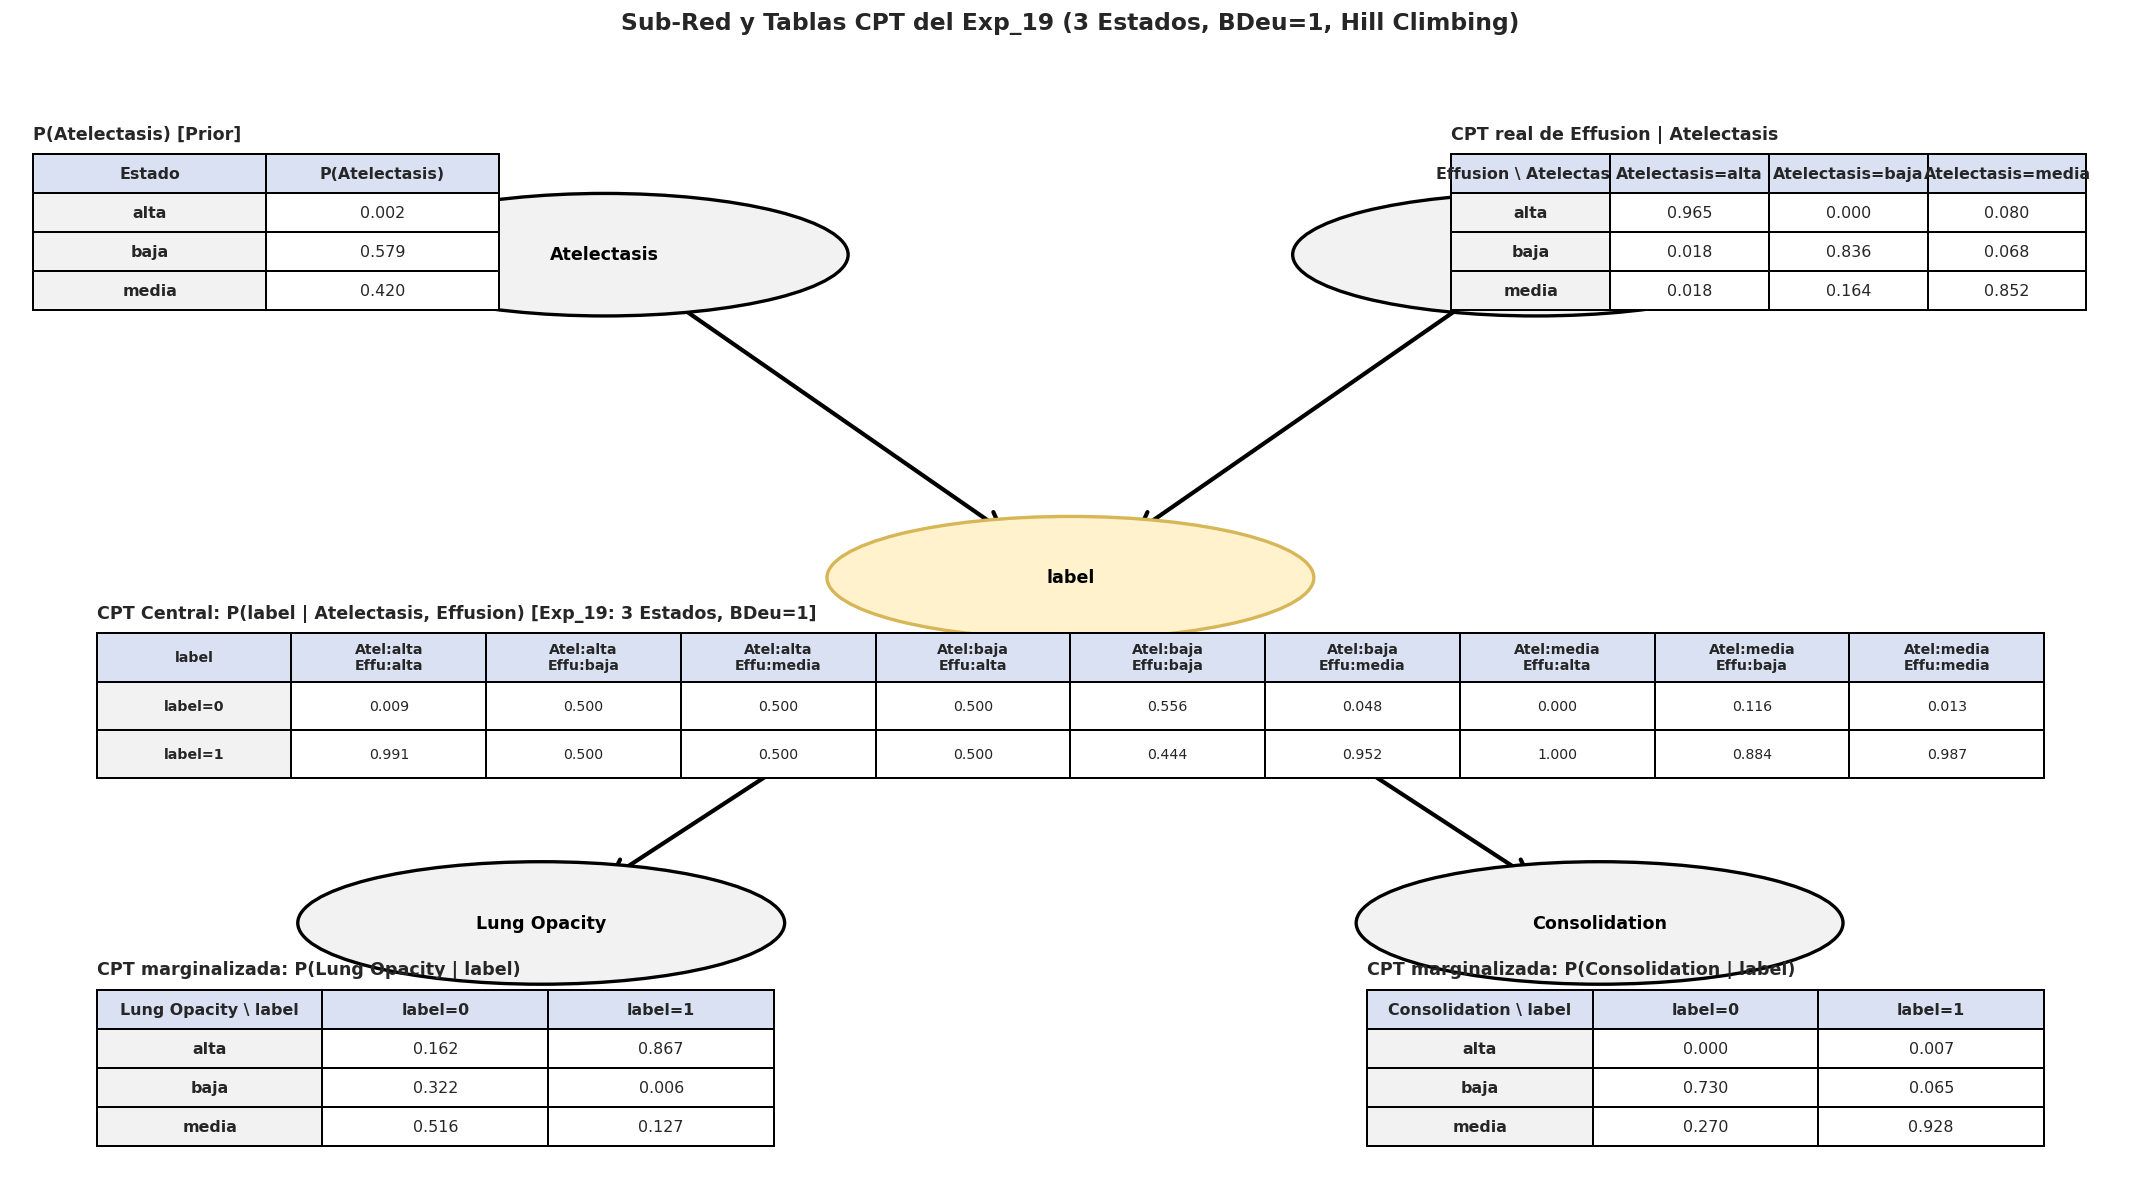

In [ ]:
# ==============================================================================
# VISUALIZADOR DE SUB-RED Y TABLAS CPT PARA EL EXP_19 (3 Estados, BDeu=1)
# Trabaja de forma aislada usando 'modelo_test' y 'train_df_test'
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, FancyArrowPatch
from sklearn.metrics import mutual_info_score
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator, HillClimbSearch

try:
    from pgmpy.estimators import BIC
    usar_bic_test = True
except ImportError:
    usar_bic_test = False

# 0. Asegurar el entorno de prueba del Exp_19 por si no se ha corrido en esta celda
print("1. Verificando entorno temporal Exp_19...")
df_tab_test = pd.read_csv('radiografias_clinicas_tabulares.csv')
df_base_test = df_tab_test.drop(columns=[c for c in ['path', 'partition', 'group', 'Pneumonia'] if c in df_tab_test.columns]).copy()

bins_3 = [-np.inf, 0.33, 0.66, np.inf]
labels_3 = ['baja', 'media', 'alta']
for col in [c for c in df_base_test.columns if c != 'label']:
    df_base_test[col] = pd.cut(df_base_test[col], bins=bins_3, labels=labels_3).astype(str)
df_base_test['label'] = df_base_test['label'].astype(str)

from sklearn.model_selection import train_test_split
train_df_test, test_df_test = train_test_split(
    df_base_test, test_size=0.2, random_state=42, stratify=df_base_test['label']
)

hc_test = HillClimbSearch(train_df_test)
est_test = hc_test.estimate(scoring_method=BIC(train_df_test)) if usar_bic_test else hc_test.estimate(scoring_method='bicscore')
modelo_test = DiscreteBayesianNetwork(est_test.edges())

estimador_test = BayesianEstimator(modelo_test, train_df_test)
cpts_test = estimador_test.get_parameters(prior_type='BDeu', equivalent_sample_size=1)
modelo_test.add_cpds(*cpts_test)

# ==============================================================================
# 1. EXTRAER NODOS Y TABLAS DIRECTAMENTE DE 'modelo_test'
# ==============================================================================
padres_reales = list(modelo_test.get_parents('label'))
hijos_reales = list(modelo_test.get_children('label'))

hijos_ordenados = sorted(
    hijos_reales,
    key=lambda col: mutual_info_score(train_df_test[col], train_df_test['label']),
    reverse=True
)
hijos_mostrar = hijos_ordenados[:2]

print("\n=== VERIFICACIÓN DIRECTA DESDE EL OBJETO 'modelo_test' (Exp_19) ===")
print(f"Padres descubiertos de 'label': {padres_reales}")
print(f"Hijos descubiertos de 'label':  {hijos_reales}")
print(f"Hijos mostrados en el gráfico:  {hijos_mostrar}\n")

print("--- CPT Oficial Interna de 'label' en pgmpy (Exp_19) ---")
print(modelo_test.get_cpds('label'))

# ==============================================================================
# 2. GRAFICAR EL DIAGRAMA Y LAS TABLAS CPT
# ==============================================================================
fig, ax = plt.subplots(figsize=(18, 10), dpi=120)
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis('off')

pos_papel = {'label': (5.0, 5.3)}
for idx, p in enumerate(padres_reales[:2]):
    pos_papel[p] = (2.8 if idx == 0 else 7.2, 8.2)
for idx, h in enumerate(hijos_mostrar):
    pos_papel[h] = (2.5 if idx == 0 else 7.5, 2.2)

aristas_reales = [(p, 'label') for p in padres_reales[:2]] + [('label', h) for h in hijos_mostrar]
for origen, destino in aristas_reales:
    x1, y1 = pos_papel[origen]
    x2, y2 = pos_papel[destino]
    flecha = FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle='->,head_length=10,head_width=6',
        lw=2.5, color='black', shrinkA=48, shrinkB=48, zorder=2
    )
    ax.add_patch(flecha)

for nodo, (x, y) in pos_papel.items():
    es_label = (nodo == 'label')
    ovalo = Ellipse(
        (x, y), width=2.3, height=1.1,
        facecolor='#FFF2CC' if es_label else '#F2F2F2',
        edgecolor='#D6B656' if es_label else 'black',
        lw=2, zorder=3
    )
    ax.add_patch(ovalo)
    ax.text(x, y, nodo, color='black', fontsize=10.5, fontweight='bold', ha='center', va='center', zorder=4)

def renderizar_cpd_real(ax, cpd_obj, titulo, coords_caja, coords_titulo):
    var_nodo = cpd_obj.variable
    estados_filas = cpd_obj.state_names[var_nodo]
    padres_cpd = cpd_obj.variables[1:]

    if len(padres_cpd) == 0:
        col_headers = ['Estado', 'P(' + var_nodo + ')']
        filas_texto = [[est, f"{ float(cpd_obj.values[i]) :.3f}"] for i, est in enumerate(estados_filas)]

    elif len(padres_cpd) == 1:
        p1 = padres_cpd[0]
        est_p1 = cpd_obj.state_names[p1]
        col_headers = [f"{var_nodo} \\ {p1}"] + [f"{p1}={e}" for e in est_p1]
        filas_texto = []
        for i, est_f in enumerate(estados_filas):
            fila = [est_f] + [f"{ float(cpd_obj.values[i, j]) :.3f}" for j in range(len(est_p1))]
            filas_texto.append(fila)

    elif len(padres_cpd) == 2:
        p1, p2 = padres_cpd[0], padres_cpd[1]
        est_p1, est_p2 = cpd_obj.state_names[p1], cpd_obj.state_names[p2]
        col_headers = [f"{var_nodo}"]
        for e1 in est_p1:
            for e2 in est_p2:
                col_headers.append(f"{p1[:4]}:{e1}\n{p2[:4]}:{e2}")

        filas_texto = []
        for k, est_f in enumerate(estados_filas):
            fila = [f"label={est_f}"]
            for i in range(len(est_p1)):
                for j in range(len(est_p2)):
                    fila.append(f"{ float(cpd_obj.values[k, i, j]) :.3f}")
            filas_texto.append(fila)

    tabla = ax.table(cellText=filas_texto, colLabels=col_headers, cellLoc='center', bbox=coords_caja, zorder=5)
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(8.5 if len(col_headers) > 5 else 9.5)

    for (r, c), cell in tabla.get_celld().items():
        cell.set_edgecolor('black')
        cell.set_linewidth(1.2)
        if r == 0:
            cell.set_facecolor('#D9E1F2')
            cell.set_text_props(weight='bold')
        elif c == 0:
            cell.set_facecolor('#F2F2F2')
            cell.set_text_props(weight='bold')
        else:
            cell.set_facecolor('white')

    ax.text(coords_titulo[0], coords_titulo[1], titulo, fontsize=10.5, fontweight='bold', ha='left', va='bottom')

# --- 1. Extraer y dibujar CPTs de los 2 Padres ---
cajas_padres = [([0.01, 0.77, 0.22, 0.14], (0.1, 9.2)), ([0.68, 0.77, 0.30, 0.14], (6.8, 9.2))]
for idx, p in enumerate(padres_reales[:2]):
    cpd_padre = modelo_test.get_cpds(p)
    padres_de_p = cpd_padre.variables[1:]
    tit_p = f"CPT real de {p} | {', '.join(padres_de_p)}" if padres_de_p else f"P({p}) [Prior]"
    renderizar_cpd_real(ax, cpd_padre, tit_p, cajas_padres[idx][0], cajas_padres[idx][1])

# --- 2. Extraer y dibujar la CPT real de 'label' ---
cpd_label = modelo_test.get_cpds('label')
renderizar_cpd_real(
    ax, cpd_label,
    f"CPT Central: P(label | {', '.join(padres_reales)}) [Exp_19: 3 Estados, BDeu=1]",
    coords_caja=[0.04, 0.35, 0.92, 0.13],
    coords_titulo=(0.4, 4.9)
)

# --- 3. Extraer y dibujar las CPTs de los Hijos ---
cajas_hijos = [([0.04, 0.02, 0.32, 0.14], (0.4, 1.7)), ([0.64, 0.02, 0.32, 0.14], (6.4, 1.7))]
for idx, h in enumerate(hijos_mostrar):
    cpd_hijo = modelo_test.get_cpds(h)
    if len(cpd_hijo.variables[1:]) == 1:
        renderizar_cpd_real(ax, cpd_hijo, f"CPT real: P({h} | label)", cajas_hijos[idx][0], cajas_hijos[idx][1])
    else:
        sub_m = DiscreteBayesianNetwork([('label', h)])
        cpd_h_limpia = BayesianEstimator(sub_m, train_df_test).get_parameters(prior_type='BDeu', equivalent_sample_size=1)[1]
        renderizar_cpd_real(ax, cpd_h_limpia, f"CPT marginalizada: P({h} | label)", cajas_hijos[idx][0], cajas_hijos[idx][1])

plt.title("Sub-Red y Tablas CPT del Exp_19 (3 Estados, BDeu=1, Hill Climbing)", fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

1. Preparando datos temporales para el Exp_19 (3 Estados)...
2. Aprendiendo estructura con Hill Climbing (Exp_19)...


  0%|          | 0/1000000 [00:00<?, ?it/s]

   Modelo temporal creado con éxito. Conexiones: 37

Padres: ['Atelectasis', 'Effusion']
Hijos : ['Lung Opacity', 'Pleural_Thickening', 'Emphysema', 'Edema', 'Mass', 'Hernia', 'Consolidation', 'Nodule']
Hijos mostrados: ['Lung Opacity', 'Consolidation']

--- LEYENDA DE ABREVIATURAS EN TABLAS ---
label ---> Label
Effusion ---> Eff
Consolidation ---> Cons
Atelectasis ---> At
Lung Opacity ---> LUNG


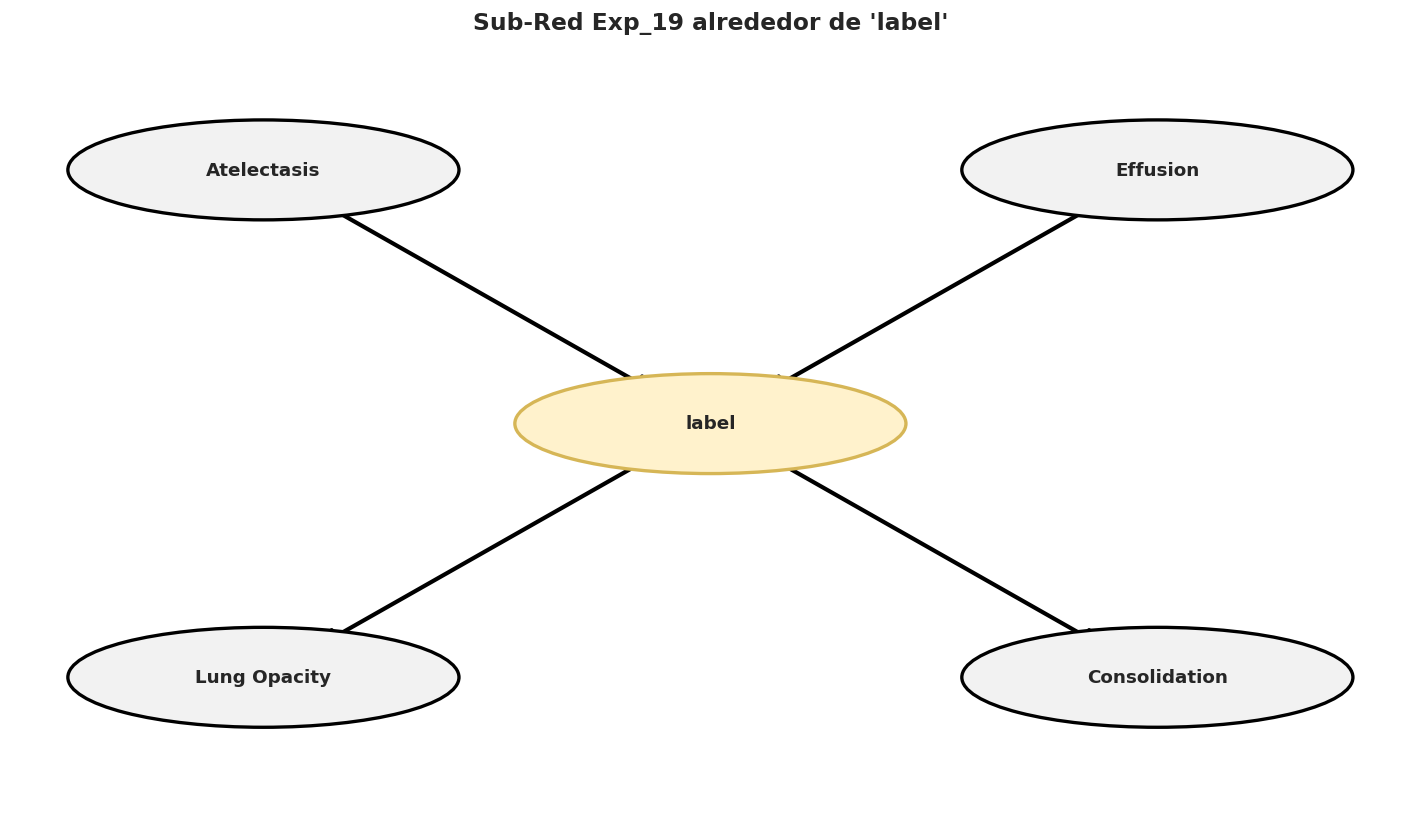

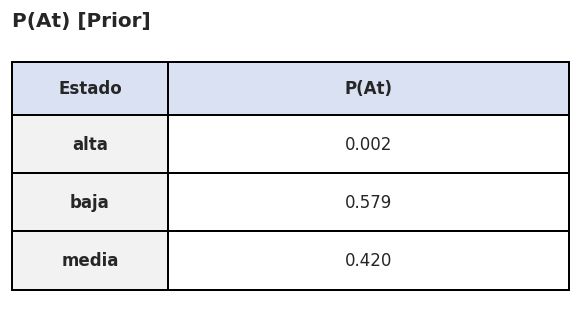

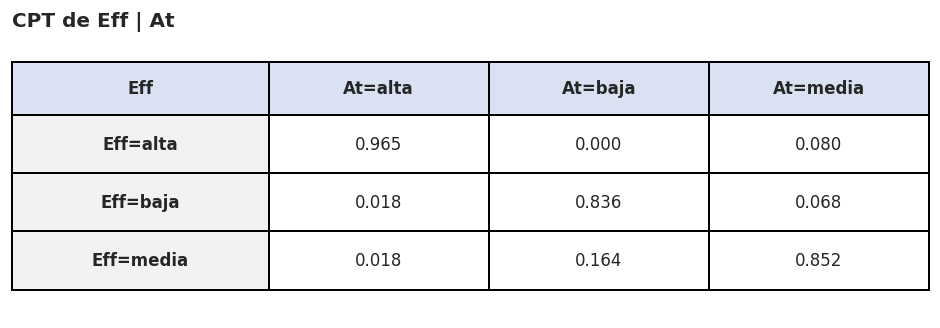

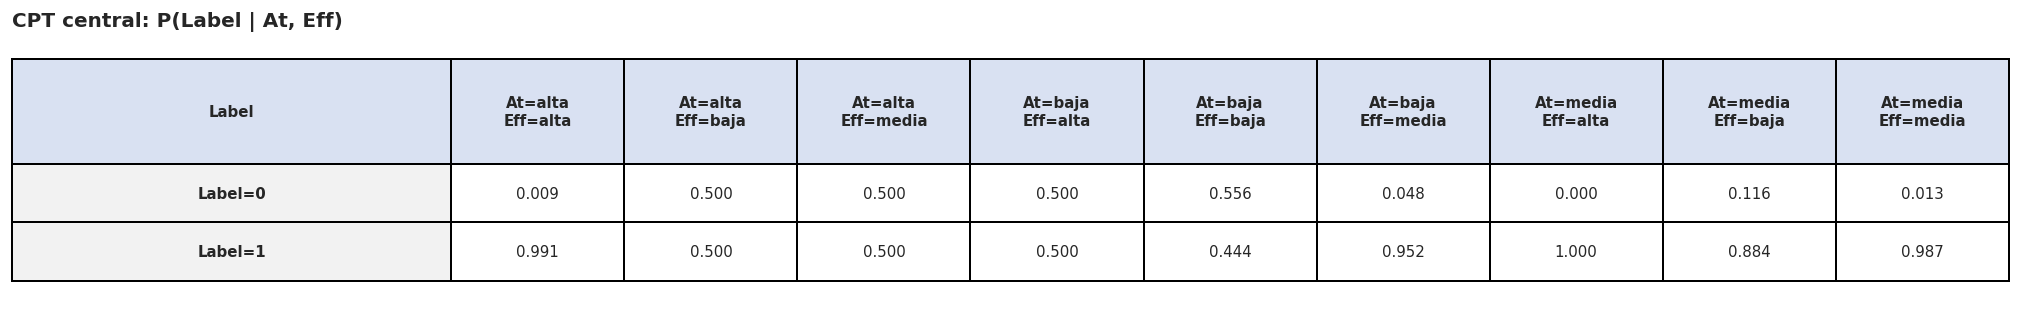

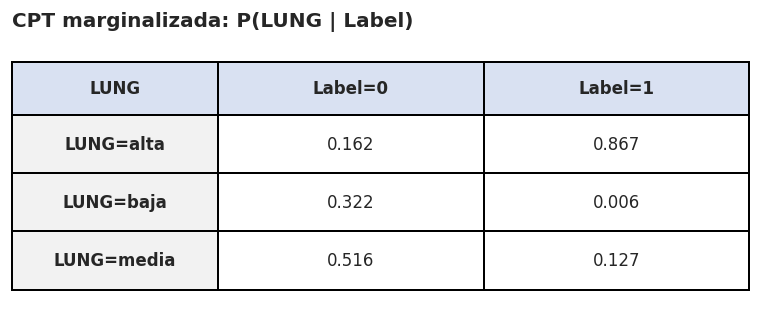

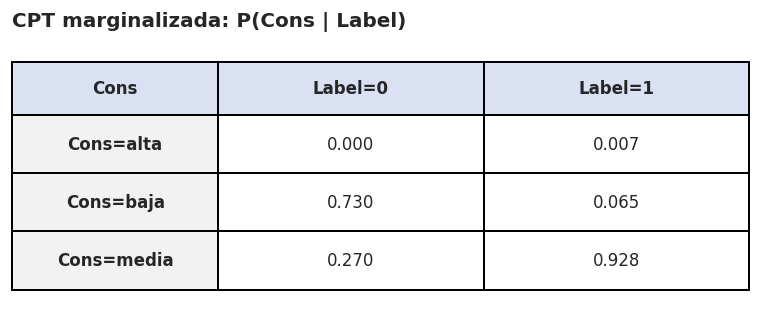

In [ ]:
# ==============================================================================
# SCRIPT DE PRUEBA AISLADO: EXP_19 (3 Estados, BDeu=1, Hill Climbing, Completo)
# Con nombres abreviados en las tablas CPD para mayor compacidad.
# ==============================================================================
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, FancyArrowPatch
from sklearn.metrics import mutual_info_score
from sklearn.model_selection import train_test_split
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator, HillClimbSearch

try:
    from pgmpy.estimators import BIC
    usar_bic_test = True
except ImportError:
    usar_bic_test = False

print("1. Preparando datos temporales para el Exp_19 (3 Estados)...")
df_tab_test = pd.read_csv('radiografias_clinicas_tabulares.csv')
df_base_test = df_tab_test.drop(columns=[c for c in ['path', 'partition', 'group', 'Pneumonia'] if c in df_tab_test.columns]).copy()

# Discretización estricta a 3 Estados (Terciles)
bins_3 = [-np.inf, 0.33, 0.66, np.inf]
labels_3 = ['baja', 'media', 'alta']
patologias_test = [c for c in df_base_test.columns if c != 'label']

for col in patologias_test:
    df_base_test[col] = pd.cut(df_base_test[col], bins=bins_3, labels=labels_3).astype(str)
df_base_test['label'] = df_base_test['label'].astype(str)

# Partición idéntica
train_df_test, test_df_test = train_test_split(
    df_base_test, test_size=0.2, random_state=42, stratify=df_base_test['label']
)

print("2. Aprendiendo estructura con Hill Climbing (Exp_19)...")
hc_test = HillClimbSearch(train_df_test)
est_test = hc_test.estimate(scoring_method=BIC(train_df_test)) if usar_bic_test else hc_test.estimate(scoring_method='bicscore')

# Creamos el modelo de prueba temporal
modelo_test = DiscreteBayesianNetwork(est_test.edges())

# Estimación con BDeu = 1 (configuración específica del Exp_19)
estimador_test = BayesianEstimator(modelo_test, train_df_test)
cpts_test = estimador_test.get_parameters(prior_type='BDeu', equivalent_sample_size=1)
modelo_test.add_cpds(*cpts_test)

print(f"   Modelo temporal creado con éxito. Conexiones: {len(modelo_test.edges())}")

# ==============================================================================
# 0. DICCIONARIO DE ABREVIATURAS PARA LAS TABLAS CPD
# ==============================================================================
def abreviar(nombre):
    mapping = {
        'Atelectasis': 'At',
        'Consolidation': 'Cons',
        'Infiltration': 'Inf',
        'Pneumothorax': 'Pneu',
        'Edema': 'Ed',
        'Emphysema': 'Emp',
        'Fibrosis': 'Fib',
        'Effusion': 'Eff',
        'Pleural_Thickening': 'Pl.Th',
        'Cardiomegaly': 'Card',
        'Nodule': 'Nod',
        'Mass': 'Mass',
        'Hernia': 'Hern',
        'Fracture': 'Frac',
        'Lung_Lesion': 'L.Les',
        'Support_Devices': 'Sup',
        'label': 'Label'
    }
    return mapping.get(nombre, nombre[:4].upper())

# ==============================================================================
# 1. NODOS A MOSTRAR (leídos del objeto 'modelo_test')
# ==============================================================================
padres_reales = list(modelo_test.get_parents('label'))
hijos_reales  = list(modelo_test.get_children('label'))

hijos_mostrar = sorted(
    hijos_reales,
    key=lambda c: mutual_info_score(train_df_test[c], train_df_test['label']),
    reverse=True
)[:2]

print("\nPadres:", padres_reales)
print("Hijos :", hijos_reales)
print("Hijos mostrados:", hijos_mostrar)

print("\n--- LEYENDA DE ABREVIATURAS EN TABLAS ---")
for n in set(padres_reales + hijos_mostrar + ['label']):
    print(f"{n} ---> {abreviar(n)}")

# ==============================================================================
# 2. DIAGRAMA (solo óvalos y flechas)
# ==============================================================================
def dibujar_diagrama(padres, hijos, titulo="Sub-Red Exp_19 alrededor de 'label'"):
    fig, ax = plt.subplots(figsize=(12, 7), dpi=120)
    ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis('off')

    def repartir(n, y):
        xs = [5.0] if n == 1 else [1.8 + i * (6.4 / (n - 1)) for i in range(n)]
        return [(x, y) for x in xs]

    pos = {'label': (5.0, 5.0)}
    for p, xy in zip(padres, repartir(len(padres), 8.3)):
        pos[p] = xy
    for h, xy in zip(hijos, repartir(len(hijos), 1.7)):
        pos[h] = xy

    aristas = [(p, 'label') for p in padres] + [('label', h) for h in hijos]
    for o, d in aristas:
        ax.add_patch(FancyArrowPatch(
            pos[o], pos[d], arrowstyle='-|>', mutation_scale=22,
            lw=2.5, color='black', shrinkA=38, shrinkB=38, zorder=2))

    for nodo, (x, y) in pos.items():
        es_label = nodo == 'label'
        ax.add_patch(Ellipse(
            (x, y), width=2.8, height=1.3,
            facecolor='#FFF2CC' if es_label else '#F2F2F2',
            edgecolor='#D6B656' if es_label else 'black', lw=2, zorder=3))
        ax.text(x, y, nodo.replace('_', '\n') if len(nodo) > 14 else nodo,
                fontsize=11, fontweight='bold', ha='center', va='center', zorder=4)

    ax.set_title(titulo, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# ==============================================================================
# 3. TABLAS (con nombres abreviados para que salgan más compactas)
# ==============================================================================
def cpd_a_tabla(cpd, ancho_wrap=16):
    from itertools import product
    var = cpd.variable
    padres = list(cpd.variables[1:])
    estados_var = cpd.state_names[var]
    valores = cpd.get_values()

    var_abrev = abreviar(var)

    if not padres:
        headers = ['Estado', f'P({var_abrev})']
        filas = [[str(e), f"{valores[i, 0]:.3f}"] for i, e in enumerate(estados_var)]
        return headers, filas

    combos = list(product(*[cpd.state_names[p] for p in padres]))
    headers = [f'{var_abrev}']
    for combo in combos:
        txt = "\n".join(
            textwrap.fill(f"{abreviar(p)}={e}", width=ancho_wrap, break_long_words=True)
            for p, e in zip(padres, combo))
        headers.append(txt)

    filas = [[f"{var_abrev}={e}"] + [f"{valores[i, j]:.3f}" for j in range(len(combos))]
             for i, e in enumerate(estados_var)]
    return headers, filas

def dibujar_tabla(cpd, titulo):
    headers, filas = cpd_a_tabla(cpd)
    ncols, nfilas = len(headers), len(filas)
    max_lineas = max(h.count("\n") + 1 for h in headers)

    ancho_fig = min(2.0 + 1.5 * ncols, 22)
    alto_fig = 1.2 + 0.45 * nfilas + 0.35 * max_lineas
    fig, ax = plt.subplots(figsize=(ancho_fig, alto_fig), dpi=120)
    ax.axis('off')

    tabla = ax.table(cellText=filas, colLabels=headers, cellLoc='center', loc='center')
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(10 if ncols <= 5 else 9)

    ancho_col0 = 0.22 if ncols > 4 else 0.28
    ancho_col = (1 - ancho_col0) / (ncols - 1) if ncols > 1 else 1
    alto_fila = 1 / (nfilas + max_lineas * 0.8 + 1)

    for (r, c), cell in tabla.get_celld().items():
        cell.set_width(ancho_col0 if c == 0 else ancho_col)
        cell.set_height(alto_fila * (max_lineas * 0.9 if r == 0 else 1))
        cell.set_edgecolor('black'); cell.set_linewidth(1.2)
        if r == 0:
            cell.set_facecolor('#D9E1F2'); cell.set_text_props(weight='bold')
        elif c == 0:
            cell.set_facecolor('#F2F2F2'); cell.set_text_props(weight='bold')
        else:
            cell.set_facecolor('white')

    ax.set_title(titulo, fontsize=12, fontweight='bold', loc='left')
    plt.tight_layout()
    plt.show()

def cpd_hijo_condicionada_a_label(h):
    cpd = modelo_test.get_cpds(h)
    if len(cpd.variables[1:]) == 1:
        return cpd, f"CPT real: P({abreviar(h)} | {abreviar('label')})"
    sub = DiscreteBayesianNetwork([('label', h)])
    cpds = BayesianEstimator(sub, train_df_test).get_parameters(
        prior_type='BDeu', equivalent_sample_size=1)
    cpd_h = next(c for c in cpds if c.variable == h)
    return cpd_h, f"CPT marginalizada: P({abreviar(h)} | {abreviar('label')})"

# ==============================================================================
# 4. EJECUTAR PRUEBA EXP_19
# ==============================================================================
dibujar_diagrama(padres_reales, hijos_mostrar)

for p in padres_reales:
    cpd = modelo_test.get_cpds(p)
    pp = cpd.variables[1:]
    tit_p = f"CPT de {abreviar(p)} | {', '.join([abreviar(x) for x in pp])}" if pp else f"P({abreviar(p)}) [Prior]"
    dibujar_tabla(cpd, tit_p)

dibujar_tabla(modelo_test.get_cpds('label'),
             f"CPT central: P({abreviar('label')} | {', '.join([abreviar(x) for x in padres_reales])})")

for h in hijos_mostrar:
    cpd_h, tit = cpd_hijo_condicionada_a_label(h)
    dibujar_tabla(cpd_h, tit)

# Comparación

1. Preparando entornos y entrenando ambos modelos para la comparativa...


  0%|          | 0/1000000 [00:00<?, ?it/s]

  0%|          | 0/1000000 [00:00<?, ?it/s]

¡Modelos evaluados con éxito! Generando gráficas comparativas...



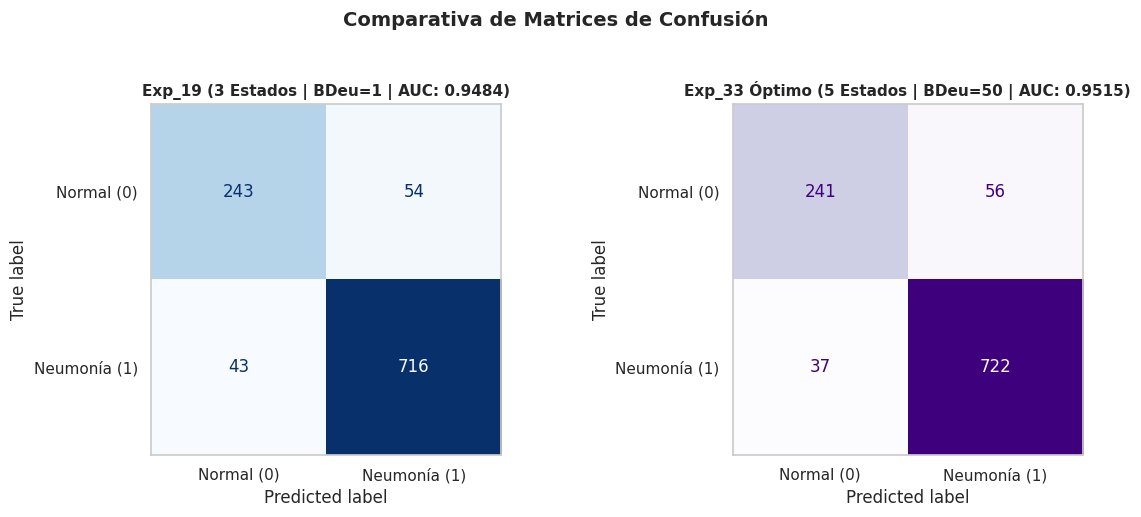

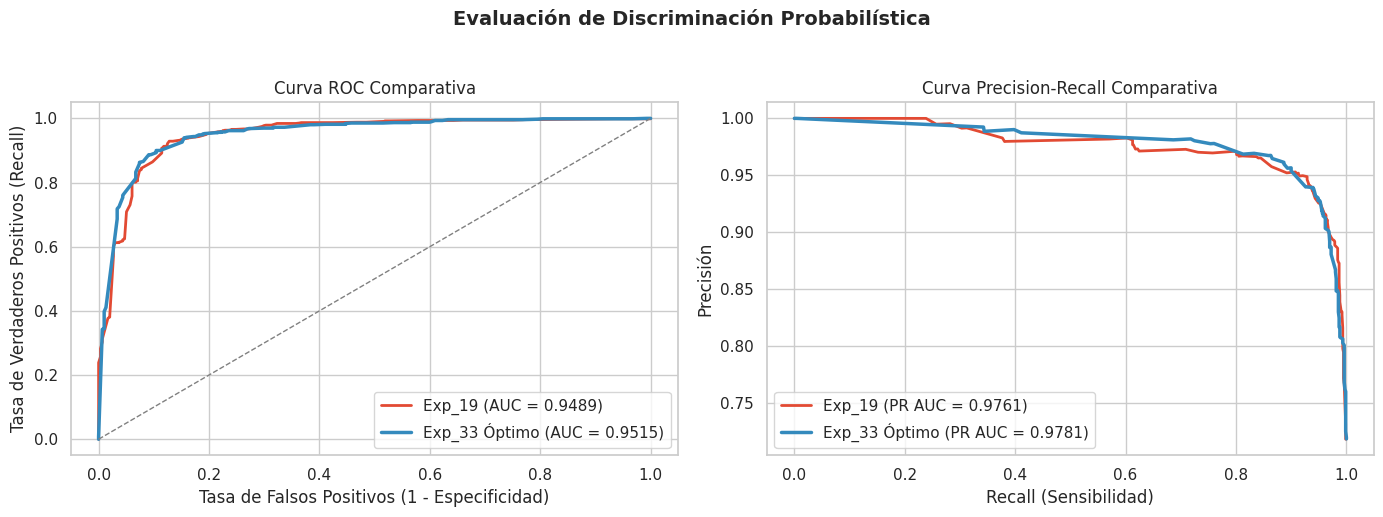

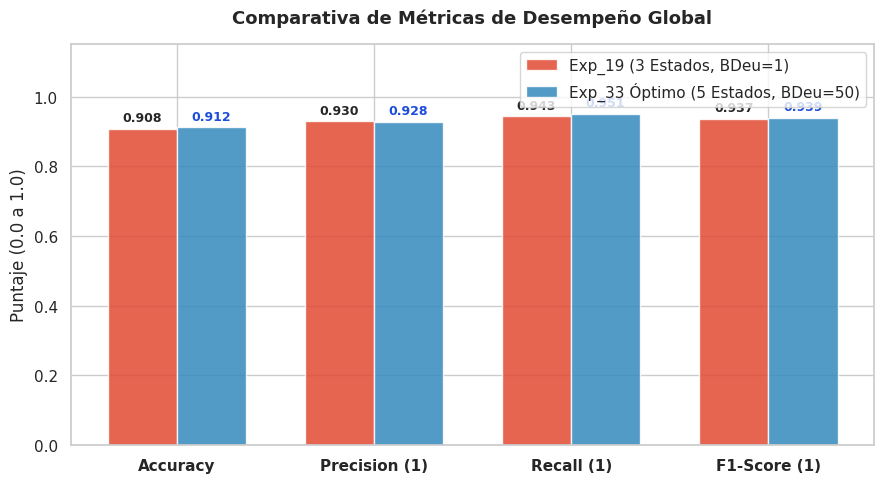

In [ ]:
# ==============================================================================
# COMPARATIVA GRÁFICA DIRECTA: EXP_19 vs. EXP_33 (ÓPTIMO)
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, precision_recall_curve,
    accuracy_score, precision_score, recall_score, f1_score
)
from sklearn.model_selection import train_test_split
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator, HillClimbSearch
from pgmpy.inference import VariableElimination

try:
    from pgmpy.estimators import BIC
    usar_bic = True
except ImportError:
    usar_bic = False

print("1. Preparando entornos y entrenando ambos modelos para la comparativa...")
df_tab = pd.read_csv('radiografias_clinicas_tabulares.csv')
nodos_ruidosos = ['Fracture', 'Hernia', 'Enlarged Cardiomediastinum', 'Cardiomegaly']

# --- MODELO A: EXP_19 (3 Estados, BDeu=1, Completo) ---
df_19 = df_tab.drop(columns=[c for c in ['path', 'partition', 'group', 'Pneumonia'] if c in df_tab.columns]).copy()
for col in [c for c in df_19.columns if c != 'label']:
    df_19[col] = pd.cut(df_19[col], bins=[-np.inf, 0.33, 0.66, np.inf], labels=['baja', 'media', 'alta']).astype(str)
df_19['label'] = df_19['label'].astype(str)

tr_19, te_19 = train_test_split(df_19, test_size=0.2, random_state=42, stratify=df_19['label'])
hc_19 = HillClimbSearch(tr_19)
est_19 = hc_19.estimate(scoring_method=BIC(tr_19)) if usar_bic else hc_19.estimate(scoring_method='bicscore')
mod_19 = DiscreteBayesianNetwork(est_19.edges())
mod_19.add_cpds(*BayesianEstimator(mod_19, tr_19).get_parameters(prior_type='BDeu', equivalent_sample_size=1))

# --- MODELO B: EXP_33 (5 Estados, BDeu=50, Ablación de Ruido) ---
df_33 = df_tab.drop(columns=[c for c in ['path', 'partition', 'group', 'Pneumonia'] + nodos_ruidosos if c in df_tab.columns]).copy()
for col in [c for c in df_33.columns if c != 'label']:
    df_33[col] = pd.cut(df_33[col], bins=[-np.inf, 0.2, 0.4, 0.6, 0.8, np.inf], labels=['muy_baja', 'baja', 'media', 'alta', 'muy_alta']).astype(str)
df_33['label'] = df_33['label'].astype(str)

tr_33, te_33 = train_test_split(df_33, test_size=0.2, random_state=42, stratify=df_33['label'])
hc_33 = HillClimbSearch(tr_33)
est_33 = hc_33.estimate(scoring_method=BIC(tr_33)) if usar_bic else hc_33.estimate(scoring_method='bicscore')
mod_33 = DiscreteBayesianNetwork(est_33.edges())
mod_33.add_cpds(*BayesianEstimator(mod_33, tr_33).get_parameters(prior_type='BDeu', equivalent_sample_size=50))

# Función auxiliar de inferencia
def evaluar_modelo(modelo, test_df):
    inf = VariableElimination(modelo)
    nodos_net = set(modelo.nodes())
    vars_act = [c for c in test_df.columns if c != 'label' and c in nodos_net]
    y_true = test_df['label'].values
    y_true_bin = (y_true == '1').astype(int)
    y_prob, y_pred = [], []
    idx_c1 = modelo.get_cpds('label').state_names['label'].index('1')

    for _, row in test_df[vars_act].iterrows():
        try:
            post = inf.query(variables=['label'], evidence=row.to_dict(), show_progress=False)
            y_prob.append(float(post.values[idx_c1]))
            y_pred.append(post.state_names['label'][post.values.argmax()])
        except:
            y_prob.append(0.0)
            y_pred.append('0')
    return y_true, y_true_bin, np.array(y_pred), np.array(y_prob)

y_t19, y_tb19, y_p19, y_prob19 = evaluar_modelo(mod_19, te_19)
y_t33, y_tb33, y_p33, y_prob33 = evaluar_modelo(mod_33, te_33)
print("¡Modelos evaluados con éxito! Generando gráficas comparativas...\n")

# ==============================================================================
# GRÁFICA 1: MATRICES DE CONFUSIÓN COMPARATIVAS (1 fila, 2 columnas)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_19 = confusion_matrix(y_t19, y_p19, labels=['0', '1'])
disp_19 = ConfusionMatrixDisplay(confusion_matrix=cm_19, display_labels=['Normal (0)', 'Neumonía (1)'])
disp_19.plot(cmap='Blues', values_format='d', ax=axes[0], colorbar=False)
axes[0].grid(False)
axes[0].set_title('Exp_19 (3 Estados | BDeu=1 | AUC: 0.9484)', fontsize=11, fontweight='bold')

cm_33 = confusion_matrix(y_t33, y_p33, labels=['0', '1'])
disp_33 = ConfusionMatrixDisplay(confusion_matrix=cm_33, display_labels=['Normal (0)', 'Neumonía (1)'])
disp_33.plot(cmap='Purples', values_format='d', ax=axes[1], colorbar=False)
axes[1].grid(False)
axes[1].set_title('Exp_33 Óptimo (5 Estados | BDeu=50 | AUC: 0.9515)', fontsize=11, fontweight='bold')

plt.suptitle('Comparativa de Matrices de Confusión', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# ==============================================================================
# GRÁFICA 2: CURVAS ROC Y PRECISION-RECALL (AMBOS MODELOS EN 2 GRÁFICOS)
# ==============================================================================
fpr19, tpr19, _ = roc_curve(y_tb19, y_prob19)
auc19 = auc(fpr19, tpr19)
prec19, rec19, _ = precision_recall_curve(y_tb19, y_prob19)
pr_auc19 = auc(rec19, prec19)

fpr33, tpr33, _ = roc_curve(y_tb33, y_prob33)
auc33 = auc(fpr33, tpr33)
prec33, rec33, _ = precision_recall_curve(y_tb33, y_prob33)
pr_auc33 = auc(rec33, prec33)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Curva ROC Combinada
axes[0].plot(fpr19, tpr19, color='#E24A33', lw=2, label=f'Exp_19 (AUC = {auc19:.4f})')
axes[0].plot(fpr33, tpr33, color='#348ABD', lw=2.5, label=f'Exp_33 Óptimo (AUC = {auc33:.4f})')
axes[0].plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
axes[0].set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
axes[0].set_ylabel('Tasa de Verdaderos Positivos (Recall)')
axes[0].set_title('Curva ROC Comparativa')
axes[0].legend(loc='lower right')

# Curva Precision-Recall Combinada
axes[1].plot(rec19, prec19, color='#E24A33', lw=2, label=f'Exp_19 (PR AUC = {pr_auc19:.4f})')
axes[1].plot(rec33, prec33, color='#348ABD', lw=2.5, label=f'Exp_33 Óptimo (PR AUC = {pr_auc33:.4f})')
axes[1].set_xlabel('Recall (Sensibilidad)')
axes[1].set_ylabel('Precisión')
axes[1].set_title('Curva Precision-Recall Comparativa')
axes[1].legend(loc='lower left')

plt.suptitle('Evaluación de Discriminación Probabilística', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# ==============================================================================
# GRÁFICA 3: RESUMEN DE MÉTRICAS EN BARRAS AGRUPADAS (UN SOLO GRÁFICO)
# ==============================================================================
metricas_nombres = ['Accuracy', 'Precision (1)', 'Recall (1)', 'F1-Score (1)']

valores_19 = [
    accuracy_score(y_t19, y_p19),
    precision_score(y_t19, y_p19, pos_label='1', zero_division=0),
    recall_score(y_t19, y_p19, pos_label='1', zero_division=0),
    f1_score(y_t19, y_p19, pos_label='1', zero_division=0)
]

valores_33 = [
    accuracy_score(y_t33, y_p33),
    precision_score(y_t33, y_p33, pos_label='1', zero_division=0),
    recall_score(y_t33, y_p33, pos_label='1', zero_division=0),
    f1_score(y_t33, y_p33, pos_label='1', zero_division=0)
]

x = np.arange(len(metricas_nombres))
width = 0.35

plt.figure(figsize=(9, 5))
barras1 = plt.bar(x - width/2, valores_19, width, label='Exp_19 (3 Estados, BDeu=1)', color='#E24A33', alpha=0.85)
barras2 = plt.bar(x + width/2, valores_33, width, label='Exp_33 Óptimo (5 Estados, BDeu=50)', color='#348ABD', alpha=0.85)

plt.ylim(0, 1.15)
plt.ylabel('Puntaje (0.0 a 1.0)')
plt.title('Comparativa de Métricas de Desempeño Global', fontsize=13, fontweight='bold', pad=15)
plt.xticks(x, metricas_nombres, fontweight='bold')
plt.legend(loc='upper right')

# Anotar valores sobre las barras
for barra in barras1:
    h = barra.get_height()
    plt.annotate(f'{h:.3f}', xy=(barra.get_x() + barra.get_width() / 2, h), xytext=(0, 3),
                 textcoords='offset points', ha='center', va='bottom', fontsize=9, fontweight='bold')

for barra in barras2:
    h = barra.get_height()
    plt.annotate(f'{h:.3f}', xy=(barra.get_x() + barra.get_width() / 2, h), xytext=(0, 3),
                 textcoords='offset points', ha='center', va='bottom', fontsize=9, fontweight='bold', color='#1D4ED8')

plt.tight_layout()
plt.show()